# Objective Quest DATAQUEST 5.0 — V7 Foundation Breakthrough

**Primary thesis:** keep the exact V2 tree/ordinal pipeline as a frozen, proven anchor, then test genuinely different open pretrained tabular foundation models. The default breakthrough path is **TabPFN-3 classifier + TabPFN-3 regressor**, evaluated with grouped OOF and combined with the V2 anchor through a smooth non-negative stack before QWK thresholding.

**Competition constraints:** only competition-provided train/test features and labels are used at task time. Foundation weights are public and pretrained on synthetic tabular tasks. No external source reconstruction, manual mapping, hardcoded test labels, leaderboard probing, SMOTE, or arbitrary feature scaling for trees.

**Kaggle:** designed for **T4×2**. Internet must be enabled for first-time public checkpoint download.


## 0. Setup & Imports


In [1]:
import os, gc, json, random, warnings, re
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import ks_2samp

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import cohen_kappa_score, mean_squared_error, roc_auc_score

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

try:
    import shap
    HAS_SHAP = True
except Exception as e:
    HAS_SHAP = False
    print("SHAP unavailable; gain importance will still run:", e)


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

seed_everything(42)
pd.set_option("display.max_columns", 250)
pd.set_option("display.max_rows", 250)
sns.set_context("notebook")
print("Environment ready")
print("LightGBM:", lgb.__version__)
print("XGBoost:", xgb.__version__)


Environment ready
LightGBM: 4.6.0
XGBoost: 3.2.0


## 1. Problem Understanding & V2 Experiment Contract


In [2]:
class CFG:
    COMPETITION_NAME = "Objective Quest DATAQUEST 5.0"
    VERSION = "v2"

    TRAIN_FILE = "train_final.csv"
    TEST_FILE = "test_final.csv"
    DICT_FILE = "data_dictionary.csv"
    SAMPLE_FILE = "sample_submission.csv"

    TARGET = "life_satisfaction"
    ID_COL = "id"
    HOUSEHOLD_COL = "household_id"

    OUTPUT_DIR = Path("/kaggle/working/oqdq5_v2") if Path("/kaggle/working").exists() else Path("./oqdq5_v2")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    # Known anchors from V1 / leaderboard.
    V1_PUBLIC_LB = 0.48003
    V1_CROSSFIT_OOF = 0.479662
    CURRENT_TOP1_PUBLIC = 0.48853

    # Repeated grouped CV.
    N_FOLDS = 5
    REPEAT_SEEDS = [42, 2026]
    N_REPEATS = len(REPEAT_SEEDS)

    # EDA-only explainability probe. Never used for final feature selection.
    PROBE_N_ESTIMATORS = 1800
    PROBE_EARLY_STOPPING = 120
    SHAP_SAMPLE = 3000

    # Nested feature selection inside each outer train fold.
    INNER_N_FOLDS = 4
    INNER_TOP_N = 135
    INNER_FS_ESTIMATORS = 1800
    INNER_FS_EARLY_STOPPING = 100

    # Final model budgets.
    LGB_N_ESTIMATORS = 5500
    XGB_N_ESTIMATORS = 5500
    CAT_ITERATIONS = 5500
    LEARNING_RATE = 0.025
    EARLY_STOPPING = 220
    VERBOSE = 400

    USE_GPU = True
    CAT_DEVICES = "0:1"

    # Sidecar branches from V2 analysis.
    RUN_LGB_CATEGORICAL = True
    RUN_XGB_CATEGORICAL = True
    RUN_MONOTONIC = True
    RUN_MULTICLASS = True
    RUN_ORDINAL = True

    # Blend selection: require real OOF gain, not tiny optimizer noise.
    MIN_BRANCH_BLEND_GAIN = 0.00025
    GREEDY_ALPHA_GRID = np.round(np.arange(0.05, 0.56, 0.05), 2)
    MAX_SELECTED_SIDECARS = 4

    # Conservative redundancy repair.
    REPAIR_MIN_ACCURACY = 0.995
    REPAIR_MIN_SUPPORT = 100

    # Submission contract discovered after V1.
    EXPECTED_TEST_ROWS = 23902
    EXPECTED_UNIQUE_TEST_IDS = 23666

    USE_SCALING = False
    USE_OVERSAMPLING = False
    USE_GENERIC_IMPUTATION = False

print({k:v for k,v in vars(CFG).items() if k.isupper()})


{'COMPETITION_NAME': 'Objective Quest DATAQUEST 5.0', 'VERSION': 'v2', 'TRAIN_FILE': 'train_final.csv', 'TEST_FILE': 'test_final.csv', 'DICT_FILE': 'data_dictionary.csv', 'SAMPLE_FILE': 'sample_submission.csv', 'TARGET': 'life_satisfaction', 'ID_COL': 'id', 'HOUSEHOLD_COL': 'household_id', 'OUTPUT_DIR': PosixPath('/kaggle/working/oqdq5_v2'), 'V1_PUBLIC_LB': 0.48003, 'V1_CROSSFIT_OOF': 0.479662, 'CURRENT_TOP1_PUBLIC': 0.48853, 'N_FOLDS': 5, 'REPEAT_SEEDS': [42, 2026], 'N_REPEATS': 2, 'PROBE_N_ESTIMATORS': 1800, 'PROBE_EARLY_STOPPING': 120, 'SHAP_SAMPLE': 3000, 'INNER_N_FOLDS': 4, 'INNER_TOP_N': 135, 'INNER_FS_ESTIMATORS': 1800, 'INNER_FS_EARLY_STOPPING': 100, 'LGB_N_ESTIMATORS': 5500, 'XGB_N_ESTIMATORS': 5500, 'CAT_ITERATIONS': 5500, 'LEARNING_RATE': 0.025, 'EARLY_STOPPING': 220, 'VERBOSE': 400, 'USE_GPU': True, 'CAT_DEVICES': '0:1', 'RUN_LGB_CATEGORICAL': True, 'RUN_XGB_CATEGORICAL': True, 'RUN_MONOTONIC': True, 'RUN_MULTICLASS': True, 'RUN_ORDINAL': True, 'MIN_BRANCH_BLEND_GAIN': 0.00

### Why V2 keeps regression at the core

V1's public score (`0.48003`) landed almost exactly between global and cross-fitted OOF. Therefore the CV framework and QWK calibration are trustworthy. Error analysis showed the biggest contribution to QWK disagreement comes from **class 1 ↔ 2**, not rare class 4. V2 therefore keeps the continuous latent-score core and searches for **better representation of subtle satisfaction differences**.


### 1.1 Auto-discover Kaggle input


In [3]:
def discover_data_dir():
    required = {CFG.TRAIN_FILE, CFG.TEST_FILE, CFG.DICT_FILE, CFG.SAMPLE_FILE}
    roots = [Path("/kaggle/input"), Path("."), Path("./data")]
    candidates = []
    for root in roots:
        if not root.exists():
            continue
        try:
            for p in root.rglob(CFG.TRAIN_FILE):
                folder = p.parent
                present = {x.name for x in folder.iterdir() if x.is_file()}
                if required.issubset(present):
                    candidates.append(folder)
        except PermissionError:
            pass
    if not candidates:
        raise FileNotFoundError(f"Attach a Kaggle dataset containing {sorted(required)}")
    candidates = sorted(set(candidates), key=lambda p: (0 if str(p).startswith('/kaggle/input') else 1, len(str(p))))
    return candidates[0]

DATA_DIR = discover_data_dir()
TRAIN_PATH = DATA_DIR / CFG.TRAIN_FILE
TEST_PATH = DATA_DIR / CFG.TEST_FILE
DICT_PATH = DATA_DIR / CFG.DICT_FILE
SAMPLE_PATH = DATA_DIR / CFG.SAMPLE_FILE
print("DATA_DIR:", DATA_DIR)


DATA_DIR: /kaggle/input/competitions/oq-dq-5


## 2. Preprocessing & Integrity Audit


In [4]:
train = pd.read_csv(TRAIN_PATH, low_memory=False)
test = pd.read_csv(TEST_PATH, low_memory=False)
data_dictionary = pd.read_csv(DICT_PATH)
sample_submission = pd.read_csv(SAMPLE_PATH)

assert CFG.TARGET in train.columns and CFG.TARGET not in test.columns
assert len(train) == 95609, len(train)
assert len(test) == CFG.EXPECTED_TEST_ROWS, len(test)
assert test[CFG.ID_COL].nunique() == CFG.EXPECTED_UNIQUE_TEST_IDS
assert sorted(train[CFG.TARGET].dropna().unique().tolist()) == [1,2,3,4]

print("train:", train.shape)
print("test:", test.shape)
print("unique test ids:", test[CFG.ID_COL].nunique())
print("sample submission rows (known misleading template):", len(sample_submission))


train: (95609, 179)
test: (23902, 178)
unique test ids: 23666
sample submission rows (known misleading template): 23902


### 2.1 Integrity audit and duplicate-safe CV


In [5]:
def integrity_audit(train_df, test_df, sample_df, dictionary_df):
    dict_names = set(dictionary_df["kolom"].astype(str)) if "kolom" in dictionary_df.columns else set()
    return {
        "train_rows": len(train_df),
        "test_rows": len(test_df),
        "train_unique_id": train_df[CFG.ID_COL].nunique(dropna=False),
        "test_unique_id": test_df[CFG.ID_COL].nunique(dropna=False),
        "train_duplicate_id_rows": int(train_df.duplicated(CFG.ID_COL, keep=False).sum()),
        "test_duplicate_id_rows": int(test_df.duplicated(CFG.ID_COL, keep=False).sum()),
        "train_exact_duplicate_rows": int(train_df.duplicated(keep=False).sum()),
        "test_exact_duplicate_rows": int(test_df.duplicated(keep=False).sum()),
        "sample_rows": len(sample_df),
        "sample_id_equals_test_id": bool(CFG.ID_COL in sample_df and np.array_equal(sample_df[CFG.ID_COL].values, test_df[CFG.ID_COL].values)),
        "dictionary_only_columns": sorted(dict_names - set(train_df.columns)),
    }

audit = integrity_audit(train, test, sample_submission, data_dictionary)
display(pd.Series(audit, name="value").to_frame())

# Same-ID train rows must agree on target. CV groups=id prevents exact duplicate leakage.
id_target_nunique = train.groupby(CFG.ID_COL)[CFG.TARGET].nunique(dropna=False)
assert int((id_target_nunique > 1).sum()) == 0

# Duplicate test IDs must truly represent identical raw rows before we aggregate predictions.
for _, g in test[test.duplicated(CFG.ID_COL, keep=False)].groupby(CFG.ID_COL):
    assert len(g.drop_duplicates()) == 1

print("Integrity checks passed. Evaluator contract = one row per unique test_final.id.")


,value
train_rows,95609
test_rows,23902
train_unique_id,94663
test_unique_id,23666
train_duplicate_id_rows,1892
test_duplicate_id_rows,472
train_exact_duplicate_rows,1892
test_exact_duplicate_rows,472
sample_rows,23902
sample_id_equals_test_id,False


Integrity checks passed. Evaluator contract = one row per unique test_final.id.


### 2.2 Repeated grouped folds


In [6]:
y = train[CFG.TARGET].astype(int).values
groups = train[CFG.ID_COL].astype(str).values
survey_year_for_strata = train["survey_year"].fillna(-1).astype(str) if "survey_year" in train.columns else pd.Series("NA", index=train.index)
strata = train[CFG.TARGET].astype(str) + "__yr_" + survey_year_for_strata

repeated_folds = []
fold_audit_rows = []
for repeat, seed in enumerate(CFG.REPEAT_SEEDS):
    cv = StratifiedGroupKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=seed)
    folds = list(cv.split(train, strata, groups=groups))
    for fold, (tr_idx, va_idx) in enumerate(folds):
        overlap = set(groups[tr_idx]).intersection(set(groups[va_idx]))
        assert not overlap
        repeated_folds.append((repeat, fold, seed, tr_idx, va_idx))
        fold_audit_rows.append({
            "repeat": repeat, "fold": fold, "seed": seed,
            "train_n": len(tr_idx), "valid_n": len(va_idx),
            "group_overlap": len(overlap),
            "valid_target_mean": float(y[va_idx].mean()),
        })

display(pd.DataFrame(fold_audit_rows))


,repeat,fold,seed,train_n,valid_n,group_overlap,valid_target_mean
0,0,0,42,76485,19124,0,1.606672
1,0,1,42,76500,19109,0,1.605893
2,0,2,42,76487,19122,0,1.611024
3,0,3,42,76491,19118,0,1.604090
4,0,4,42,76473,19136,0,1.604776
5,1,0,2026,76501,19108,0,1.604459
6,1,1,2026,76477,19132,0,1.605373
7,1,2,2026,76476,19133,0,1.610255
8,1,3,2026,76483,19126,0,1.611994
9,1,4,2026,76499,19110,0,1.600366


### 2.3 Fold-safe redundancy-aware repair


In [7]:
REPAIR_PAIRS = [
    ("data_year", "survey_year"),
    ("survey_year", "data_year"),
    ("interview_month", "interview_quarter"),
    ("food_security_4cat", "food_security_3cat"),
    ("cancer_types_count", "cancer_ever"),
    ("ecigarette_status", "ever_used_ecigarette"),
    ("children_in_family", "children_in_household"),
    ("children_in_household", "children_in_family"),
    ("smoking_status", "ever_smoked"),
    ("health_insurance_type", "private_health_insurance"),
    ("marital_status_detailed", "marital_status"),
]

SPECIAL_CODES = {
    "weight_pounds": {996, 997, 999},
    "height_inches": {96, 97, 98, 99},
    "age": {97, 99},
    "hours_worked_per_week": {990},
    "days_missed_work": {997, 998, 999},
    "income_to_poverty_ratio": {110},
}


def learn_mode_mapping(df, src, dst, min_support=100):
    if src not in df.columns or dst not in df.columns:
        return None
    pairs = df[[src, dst]].dropna()
    if len(pairs) < min_support:
        return None
    mapping = pairs.groupby(src)[dst].agg(lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan).to_dict()
    pred = pairs[src].map(mapping)
    return {"mapping": mapping, "accuracy": float((pred.values == pairs[dst].values).mean()), "support": len(pairs)}


class FoldPreprocessor:
    def __init__(self, min_accuracy=0.995, min_support=100):
        self.min_accuracy = min_accuracy
        self.min_support = min_support
        self.repair_rules_ = {}
        self.repair_report_ = None

    def fit(self, df):
        rows=[]
        for src,dst in REPAIR_PAIRS:
            learned = learn_mode_mapping(df, src, dst, self.min_support)
            if learned is None:
                continue
            accepted = learned["accuracy"] >= self.min_accuracy
            rows.append({"source":src,"destination":dst,"accuracy":learned["accuracy"],"support":learned["support"],"accepted":accepted})
            if accepted:
                self.repair_rules_[(src,dst)] = learned["mapping"]
        self.repair_report_ = pd.DataFrame(rows)
        return self

    def transform(self, df):
        out = df.drop(columns=[CFG.TARGET], errors="ignore").copy()
        base_cols = [c for c in out.columns if c not in [CFG.ID_COL, CFG.HOUSEHOLD_COL]]
        out["row_missing_count_raw"] = out[base_cols].isna().sum(axis=1).astype(np.int16)

        before_missing = out[base_cols].isna().sum(axis=1)
        for (src,dst),mapping in self.repair_rules_.items():
            if src not in out or dst not in out:
                continue
            mask = out[dst].isna() & out[src].notna()
            if mask.any():
                inferred = out.loc[mask,src].map(mapping)
                idx = inferred[inferred.notna()].index
                out.loc[idx,dst] = inferred.loc[idx]
        after_missing = out[base_cols].isna().sum(axis=1)
        out["row_missing_count_after_repair"] = after_missing.astype(np.int16)
        out["repaired_value_count"] = (before_missing-after_missing).astype(np.int16)

        special_cols=[]
        for col,codes in SPECIAL_CODES.items():
            if col in out.columns:
                flag = f"{col}__special_code"
                out[flag] = out[col].isin(codes).astype(np.int8)
                special_cols.append(flag)
        out["special_code_count"] = out[special_cols].sum(axis=1).astype(np.int16) if special_cols else 0
        return out


### 2.4 V2 semantic survey-code representation

V1 retained codes such as `7/8/9` as ordinary numbers in many coded variables. V2 parses **explicit valid codes from `data_dictionary.csv`** and creates:

- `feature` — raw code, unchanged;
- `feature__semantic` — only dictionary-valid codes, nonstandard codes become `NaN`;
- `feature__nonstandard` — indicator that the observed code is outside the documented valid set.

This is deliberately additive: V2 never silently destroys the raw code.


In [8]:
def parse_valid_codes(value_text):
    if pd.isna(value_text):
        return None
    s = str(value_text).strip()
    if not s or s.lower() in {"numerik", "nilai tahun", "kode numerik"}:
        return None

    # Explicit mappings: 1=..., 2=..., ...
    matches = re.findall(r"(?:^|,)\s*(-?\d+(?:\.\d+)?)\s*=", s)
    if matches:
        vals = sorted({float(x) for x in matches})
        return vals if 1 <= len(vals) <= 30 else None

    # Simple integer range, e.g. 1-12 or 18-85. Keep only compact coded ranges.
    m = re.fullmatch(r"\s*(-?\d+)\s*-\s*(-?\d+)\+?\s*", s)
    if m:
        lo,hi = map(int,m.groups())
        if 0 <= hi-lo <= 30:
            return [float(x) for x in range(lo,hi+1)]
        return None

    # Bare comma-separated numeric list (e.g. survey years).
    parts = [p.strip() for p in s.split(',')]
    if 1 < len(parts) <= 30:
        try:
            return sorted({float(p) for p in parts})
        except Exception:
            return None
    return None


def build_dictionary_valid_code_map(dictionary_df, feature_names):
    result={}
    if not {"kolom","nilai"}.issubset(dictionary_df.columns):
        return result
    for _,row in dictionary_df.iterrows():
        col=str(row["kolom"])
        if col not in feature_names:
            continue
        vals=parse_valid_codes(row["nilai"])
        if vals is not None:
            result[col]=set(vals)
    return result

DICT_VALID_CODES = build_dictionary_valid_code_map(data_dictionary, set(test.columns))
print("Dictionary-coded columns parsed:", len(DICT_VALID_CODES))

# Only create semantic copies where nonstandard observed values actually exist.
combined_for_audit = pd.concat([train.drop(columns=[CFG.TARGET]), test], axis=0, ignore_index=True)
SEMANTIC_CODE_COLS=[]
semantic_audit=[]
for col,valid in DICT_VALID_CODES.items():
    if col not in combined_for_audit:
        continue
    numeric = pd.to_numeric(combined_for_audit[col], errors="coerce")
    nonstd = numeric.notna() & ~numeric.isin(valid)
    if nonstd.any():
        SEMANTIC_CODE_COLS.append(col)
        semantic_audit.append({
            "feature":col,
            "valid_codes":sorted(valid),
            "nonstandard_rows":int(nonstd.sum()),
            "nonstandard_rate":float(nonstd.mean()),
            "observed_nonstandard":sorted(numeric[nonstd].dropna().unique().tolist())[:20],
        })

semantic_audit_df = pd.DataFrame(semantic_audit).sort_values("nonstandard_rate", ascending=False)
print("Columns receiving dual semantic representation:", len(SEMANTIC_CODE_COLS))
display(semantic_audit_df.head(40))


Dictionary-coded columns parsed: 161
Columns receiving dual semantic representation: 150


,feature,valid_codes,nonstandard_rows,nonstandard_rate,observed_nonstandard
68,child_government_insurance,"[1.0, 2.0]",110110,0.921338,"[3.0, 7.0, 9.0]"
70,other_government_insurance,"[1.0, 2.0]",109750,0.918326,"[3.0, 7.0, 9.0]"
69,state_health_plan,"[1.0, 2.0]",109308,0.914627,"[3.0, 7.0, 9.0]"
71,military_health_insurance,"[1.0, 2.0]",103164,0.863218,"[3.0, 7.0, 9.0]"
52,low_income_government_insurance,"[1.0, 2.0]",96387,0.806512,"[3.0, 7.0, 9.0]"
141,income_poverty_category,"[1.0, 2.0, 3.0, 4.0]",94434,0.790170,"[5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13..."
123,legal_marital_status,"[1.0, 2.0]",91685,0.767168,"[3.0, 4.0, 5.0, 9.0]"
124,parental_status,"[1.0, 2.0]",82382,0.689326,"[3.0, 9.0]"
5,max_education_in_family,"[1.0, 2.0, 3.0, 4.0]",82222,0.687987,"[5.0, 6.0, 7.0, 8.0, 9.0, 10.0]"
3,education_level,"[1.0, 2.0, 3.0, 4.0]",73348,0.613734,"[5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 97.0, 99.0, 99..."


## 3. Fitting for Explainable AI (EDA-only probe)


In [9]:
def qwk(y_true, y_pred_class):
    return cohen_kappa_score(np.asarray(y_true), np.asarray(y_pred_class), weights="quadratic")


def apply_thresholds(pred, thresholds):
    t=np.sort(np.asarray(thresholds,dtype=float))
    return np.digitize(np.asarray(pred), bins=t).astype(int)+1


def initial_thresholds_from_distribution(y_true, continuous_pred):
    counts=pd.Series(y_true).value_counts(normalize=True).sort_index()
    cum=np.cumsum([counts.get(k,0.0) for k in [1,2,3]])
    return np.quantile(continuous_pred, np.clip(cum,0.001,0.999))


def optimize_thresholds(y_true, continuous_pred, starts=None, maxiter=160):
    y_true=np.asarray(y_true)
    p=np.asarray(continuous_pred,dtype=float)
    if starts is None:
        starts=[initial_thresholds_from_distribution(y_true,p), np.array([1.55,2.03,2.52])]
    best=None
    for start in starts:
        start=np.sort(np.asarray(start,dtype=float))
        def objective(t):
            ts=np.sort(t)
            if np.min(np.diff(ts)) < 0.03:
                return 1e3
            return -qwk(y_true, apply_thresholds(p,ts))
        res=minimize(objective,start,method="Nelder-Mead",options={"maxiter":maxiter,"xatol":1e-5,"fatol":1e-7})
        ts=np.sort(res.x)
        score=qwk(y_true,apply_thresholds(p,ts))
        if best is None or score>best[1]:
            best=(ts,score)
    return best


def make_basic_engineered_for_probe(raw_df):
    pre=FoldPreprocessor(CFG.REPAIR_MIN_ACCURACY,CFG.REPAIR_MIN_SUPPORT).fit(raw_df)
    return pre.transform(raw_df)

# Probe uses a held-out grouped split only for understanding / EDA. It NEVER determines final outer-fold features.
probe_cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=777)
probe_tr_idx,probe_va_idx=next(probe_cv.split(train,strata,groups=groups))
probe_pre=FoldPreprocessor(CFG.REPAIR_MIN_ACCURACY,CFG.REPAIR_MIN_SUPPORT).fit(train.iloc[probe_tr_idx])
X_probe_tr=probe_pre.transform(train.iloc[probe_tr_idx])
X_probe_va=probe_pre.transform(train.iloc[probe_va_idx])

probe_features=[c for c in X_probe_tr.columns if c not in [CFG.ID_COL,CFG.HOUSEHOLD_COL]]
probe=lgb.LGBMRegressor(
    objective="regression_l2",n_estimators=CFG.PROBE_N_ESTIMATORS,learning_rate=0.03,
    num_leaves=31,min_child_samples=40,colsample_bytree=0.85,subsample=0.85,subsample_freq=1,
    reg_lambda=4.0,random_state=777,n_jobs=-1,verbosity=-1,
)
probe.fit(X_probe_tr[probe_features],y[probe_tr_idx],eval_set=[(X_probe_va[probe_features],y[probe_va_idx])],
          callbacks=[lgb.early_stopping(CFG.PROBE_EARLY_STOPPING,verbose=False)])
probe_pred=probe.predict(X_probe_va[probe_features],num_iteration=probe.best_iteration_)
probe_t,probe_qwk=optimize_thresholds(y[probe_va_idx],probe_pred)
print("EDA-only probe QWK:", round(probe_qwk,6), "thresholds:", np.round(probe_t,5))

probe_importance=pd.DataFrame({"feature":probe_features,"gain":probe.booster_.feature_importance(importance_type="gain")}).sort_values("gain",ascending=False)
probe_importance["gain_norm"]=probe_importance["gain"]/max(probe_importance["gain"].sum(),1e-12)
display(probe_importance.head(30))

if HAS_SHAP:
    sample_idx=np.random.default_rng(42).choice(len(X_probe_va),size=min(CFG.SHAP_SAMPLE,len(X_probe_va)),replace=False)
    explainer=shap.TreeExplainer(probe)
    sv=explainer.shap_values(X_probe_va.iloc[sample_idx][probe_features])
    shap_imp=pd.DataFrame({"feature":probe_features,"mean_abs_shap":np.abs(np.asarray(sv)).mean(axis=0)}).sort_values("mean_abs_shap",ascending=False)
    display(shap_imp.head(30))


EDA-only probe QWK: 0.480638 thresholds: [1.54167 2.02251 2.44342]


,feature,gain,gain_norm
66,depression_frequency,41346.881955,0.291088
143,general_health_status,36025.915717,0.253627
72,anxiety_frequency,6496.541354,0.045737
98,marital_status,5765.101996,0.040587
5,difficulty_social_activities,4212.039727,0.029653
92,marital_status_detailed,3044.504670,0.021434
54,worry_about_medical_costs,2959.910293,0.020838
3,income_to_poverty_ratio,2678.460127,0.018857
130,difficulty_remembering,2021.751212,0.014233
158,anxiety_level,1769.972799,0.012461


,feature,mean_abs_shap
143,general_health_status,0.124050
66,depression_frequency,0.092669
98,marital_status,0.039683
72,anxiety_frequency,0.039302
54,worry_about_medical_costs,0.028988
92,marital_status_detailed,0.019358
5,difficulty_social_activities,0.017400
3,income_to_poverty_ratio,0.016994
174,sex,0.016746
158,anxiety_level,0.016573


## 4. EDA — Hidden Gems, Missingness, Relationships, and V1 Error Priorities


### 4.1 Target distribution and V1 leaderboard anchor


,count,share
life_satisfaction,,
1,42968,0.449414
2,48189,0.504022
3,3559,0.037225
4,893,0.009340


V1 Public LB: 0.48003
V1 Cross-fitted OOF: 0.479662
Gap to current Top 1: 0.0085


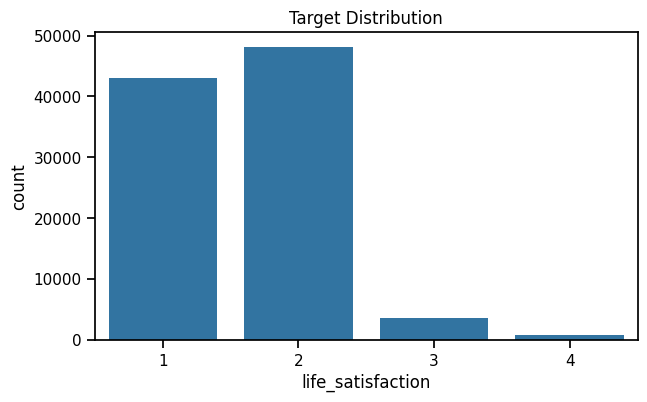

In [10]:
target_counts=train[CFG.TARGET].value_counts().sort_index()
target_dist=(target_counts/len(train)).rename("share")
display(pd.concat([target_counts.rename("count"),target_dist],axis=1))
print("V1 Public LB:",CFG.V1_PUBLIC_LB)
print("V1 Cross-fitted OOF:",CFG.V1_CROSSFIT_OOF)
print("Gap to current Top 1:",round(CFG.CURRENT_TOP1_PUBLIC-CFG.V1_PUBLIC_LB,5))

plt.figure(figsize=(7,4))
sns.countplot(data=train,x=CFG.TARGET)
plt.title("Target Distribution")
plt.show()


### 4.2 Missingness remains a feature


In [11]:
raw_feature_cols=[c for c in test.columns if c not in [CFG.ID_COL,CFG.HOUSEHOLD_COL]]
row_missing=train[raw_feature_cols].isna().sum(axis=1)
missing_target=pd.DataFrame({"missing_count":row_missing,"target":train[CFG.TARGET]})
missing_target["missing_bin"]=pd.qcut(missing_target["missing_count"],q=10,duplicates="drop")
display(missing_target.groupby("missing_bin",observed=True).agg(n=("target","size"),mean_target=("target","mean"),mean_missing=("missing_count","mean")))

miss=pd.DataFrame({
    "train_missing":train[raw_feature_cols].isna().mean(),
    "test_missing":test[raw_feature_cols].isna().mean(),
})
miss["abs_diff"]=(miss.train_missing-miss.test_missing).abs()
display(miss.sort_values("train_missing",ascending=False).head(35))


,n,mean_target,mean_missing
missing_bin,,,
"(3.999, 15.0]",12158,1.567034,13.147722
"(15.0, 17.0]",8663,1.542884,16.522683
"(17.0, 19.0]",9668,1.532065,18.505482
"(19.0, 21.0]",9191,1.538135,20.487977
"(21.0, 24.0]",10703,1.542932,22.906568
"(24.0, 27.0]",7398,1.603001,25.916058
"(27.0, 31.0]",9753,1.655183,29.588742
"(31.0, 34.0]",9417,1.685462,33.028565
"(34.0, 38.0]",11229,1.698816,36.379998


,train_missing,test_missing,abs_diff
flu_vaccine_year,0.538485,0.542800,0.004315
flu_vaccine_month,0.534291,0.540833,0.006543
ever_married,0.521112,0.520919,0.000193
gestational_diabetes_ever,0.500152,0.492051,0.008101
works_full_time,0.485854,0.485692,0.000162
hours_worked_per_week,0.485080,0.484102,0.000978
insurance_marketplace_plan1,0.449884,0.452180,0.002295
days_missed_work,0.440147,0.437871,0.002276
has_paid_sick_leave,0.439645,0.439628,0.000016
employer_offers_insurance,0.439341,0.435361,0.003980


### 4.3 Semantic outliers / undocumented survey codes


In [12]:
display(semantic_audit_df.head(50))

# V1 continuous sentinel audit retained for physical/continuous fields.
rows=[]
for col,codes in SPECIAL_CODES.items():
    if col in train:
        for val in sorted(codes):
            mask=train[col].eq(val)
            rows.append({"feature":col,"code":val,"train_n":int(mask.sum()),"target_mean":float(train.loc[mask,CFG.TARGET].mean()) if mask.any() else np.nan,"test_n":int(test[col].eq(val).sum())})
display(pd.DataFrame(rows))


,feature,valid_codes,nonstandard_rows,nonstandard_rate,observed_nonstandard
68,child_government_insurance,"[1.0, 2.0]",110110,0.921338,"[3.0, 7.0, 9.0]"
70,other_government_insurance,"[1.0, 2.0]",109750,0.918326,"[3.0, 7.0, 9.0]"
69,state_health_plan,"[1.0, 2.0]",109308,0.914627,"[3.0, 7.0, 9.0]"
71,military_health_insurance,"[1.0, 2.0]",103164,0.863218,"[3.0, 7.0, 9.0]"
52,low_income_government_insurance,"[1.0, 2.0]",96387,0.806512,"[3.0, 7.0, 9.0]"
141,income_poverty_category,"[1.0, 2.0, 3.0, 4.0]",94434,0.790170,"[5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13..."
123,legal_marital_status,"[1.0, 2.0]",91685,0.767168,"[3.0, 4.0, 5.0, 9.0]"
124,parental_status,"[1.0, 2.0]",82382,0.689326,"[3.0, 9.0]"
5,max_education_in_family,"[1.0, 2.0, 3.0, 4.0]",82222,0.687987,"[5.0, 6.0, 7.0, 8.0, 9.0, 10.0]"
3,education_level,"[1.0, 2.0, 3.0, 4.0]",73348,0.613734,"[5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 97.0, 99.0, 99..."


,feature,code,train_n,target_mean,test_n
0,weight_pounds,996,5836,1.738177,1446
1,weight_pounds,997,919,1.576714,230
2,weight_pounds,999,729,1.722908,158
3,height_inches,96,5829,1.739578,1441
4,height_inches,97,88,1.511364,20
5,height_inches,98,47,1.638298,7
6,height_inches,99,202,1.712871,52
7,age,97,168,1.541667,43
8,age,99,18,1.722222,4
9,hours_worked_per_week,990,482,1.582988,133


### 4.4 Train-test drift sanity check


In [13]:
def total_variation_distance(a,b):
    av=a.value_counts(normalize=True,dropna=False)
    bv=b.value_counts(normalize=True,dropna=False)
    idx=av.index.union(bv.index)
    return 0.5*np.abs(av.reindex(idx,fill_value=0)-bv.reindex(idx,fill_value=0)).sum()

drift_rows=[]
for c in raw_feature_cols:
    a=train[c]; b=test[c]
    nunique=max(a.nunique(dropna=True),b.nunique(dropna=True))
    if nunique<=30:
        drift=total_variation_distance(a,b)
        kind="TV"
    else:
        aa=pd.to_numeric(a,errors="coerce").dropna(); bb=pd.to_numeric(b,errors="coerce").dropna()
        drift=ks_2samp(aa,bb).statistic if len(aa) and len(bb) else np.nan
        kind="KS"
    drift_rows.append({"feature":c,"metric":kind,"drift":drift})
drift_df=pd.DataFrame(drift_rows).sort_values("drift",ascending=False)
display(drift_df.head(35))


,feature,metric,drift
18,income_poverty_category,TV,0.012106
78,height_inches,TV,0.011981
12,flu_vaccine_month,TV,0.010875
32,delayed_prescription_to_save_money,TV,0.010048
54,worry_about_medical_costs,TV,0.009993
38,gestational_diabetes_ever,TV,0.009889
162,years_in_current_home,TV,0.009847
154,skipped_medication_to_save_money,TV,0.009828
47,depression_ever,TV,0.009814
73,took_prescription_medication,TV,0.009431


### 4.5 Correlation heatmap on strongest probe features


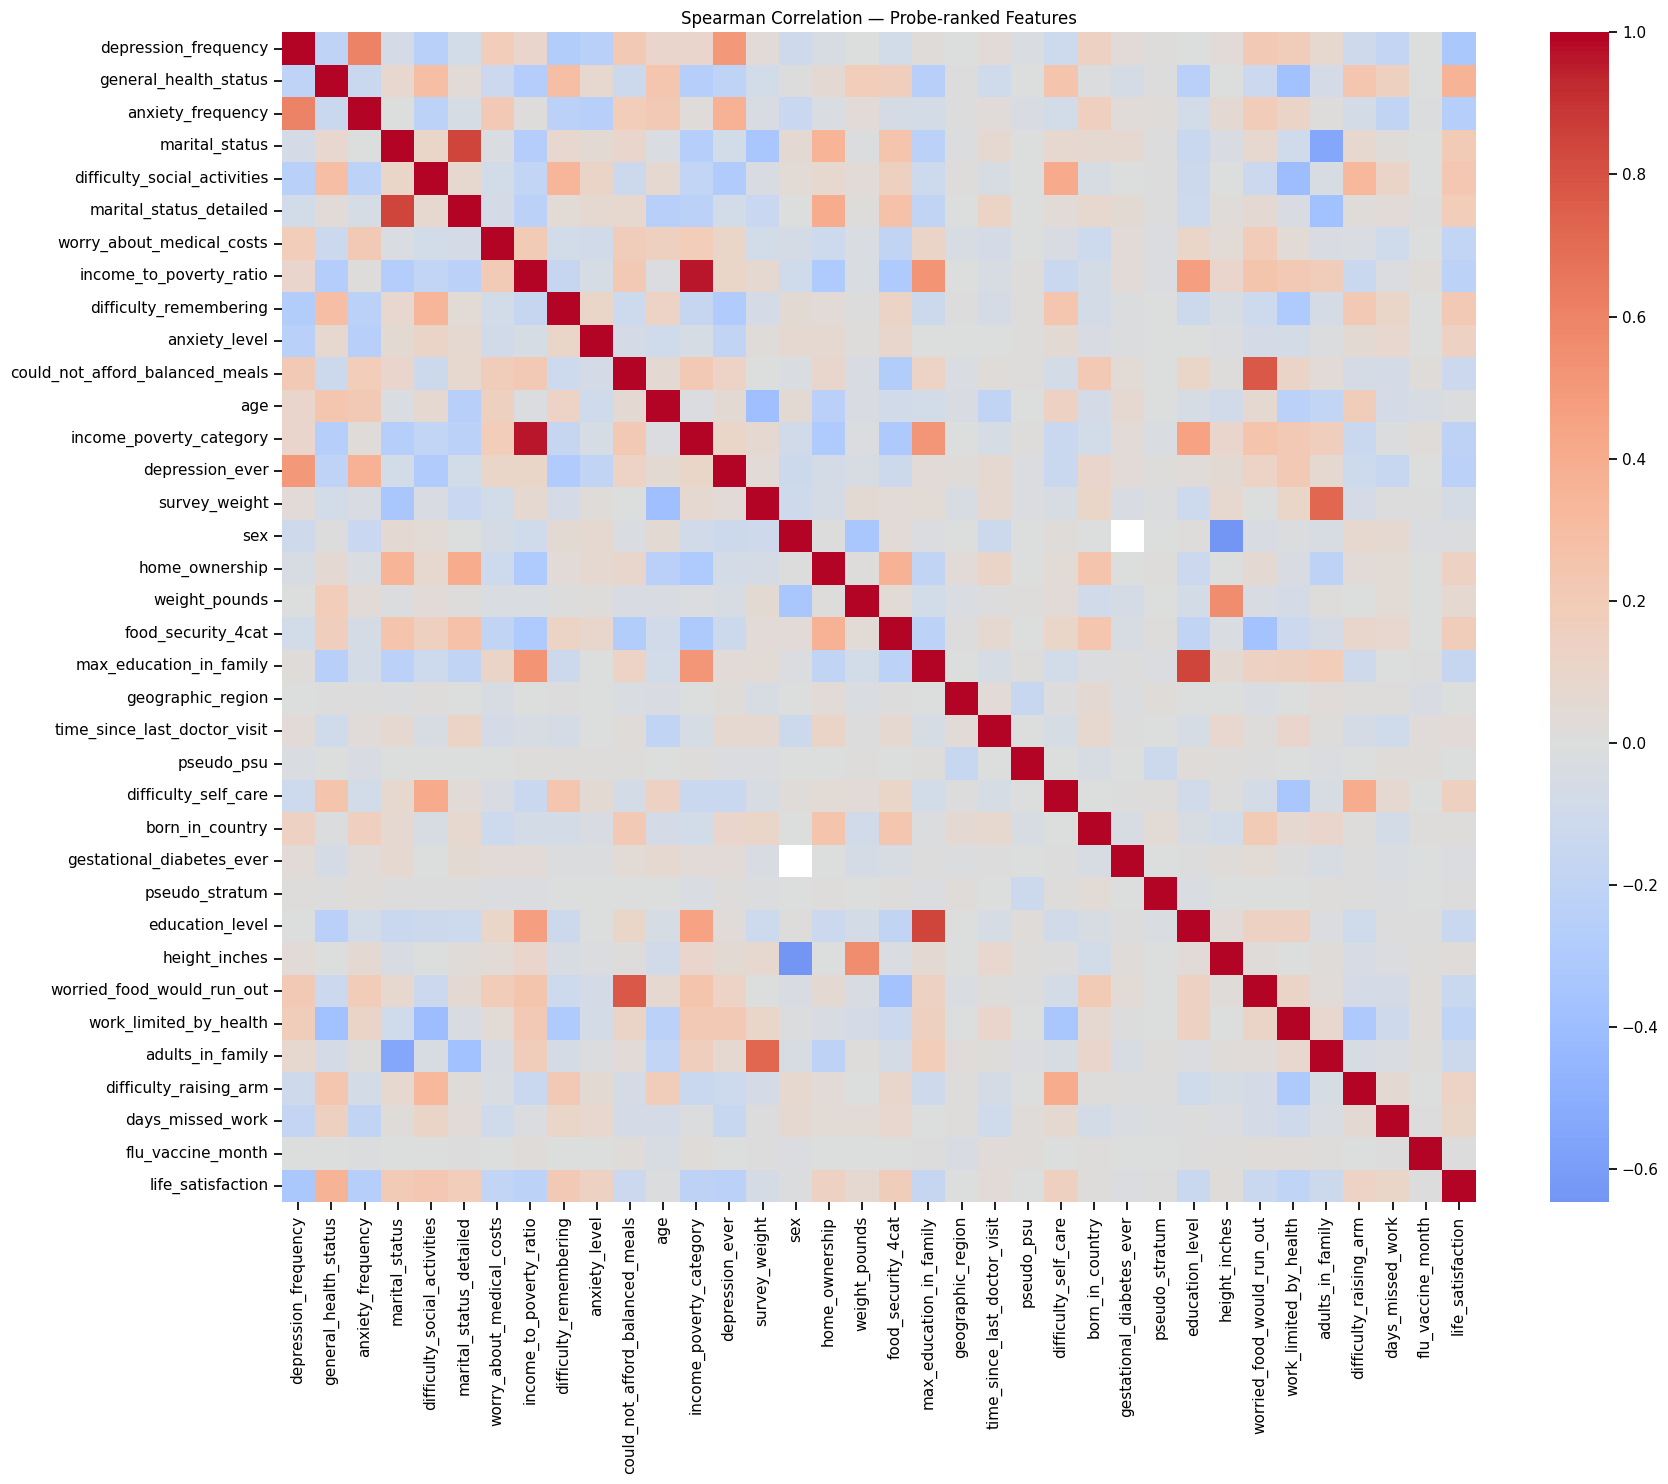

In [14]:
top_numeric=[c for c in probe_importance.feature.head(35) if c in train.columns]
corr_frame=train[top_numeric+[CFG.TARGET]].apply(pd.to_numeric,errors="coerce")
plt.figure(figsize=(18,15))
sns.heatmap(corr_frame.corr(method="spearman"),cmap="coolwarm",center=0)
plt.title("Spearman Correlation — Probe-ranked Features")
plt.tight_layout(); plt.show()


### 4.6 High-value interaction heatmaps


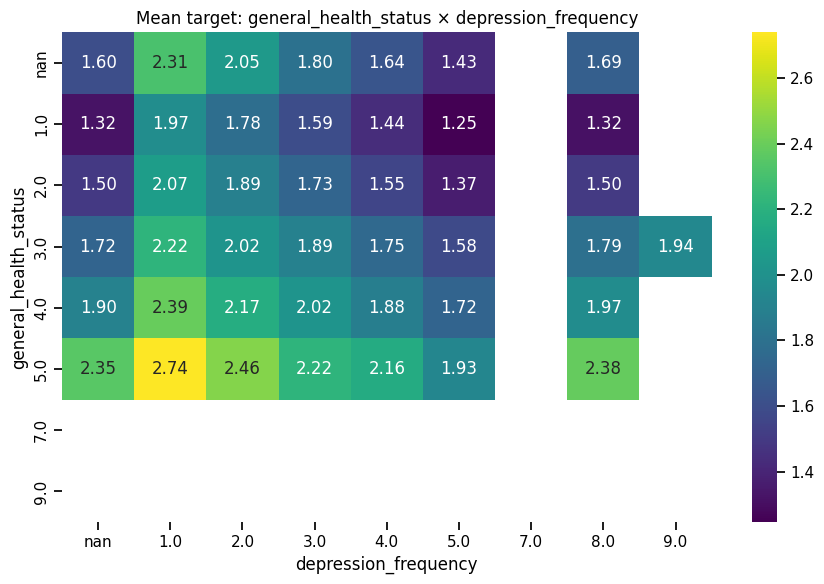

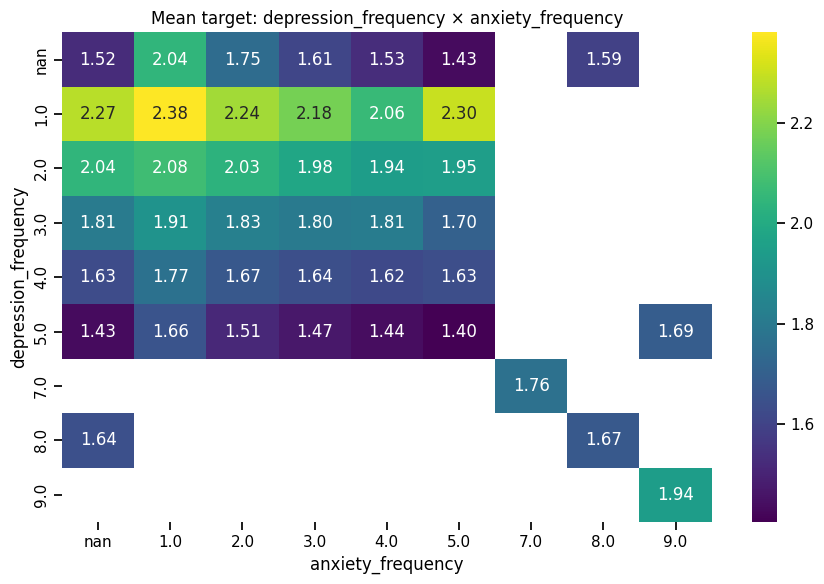

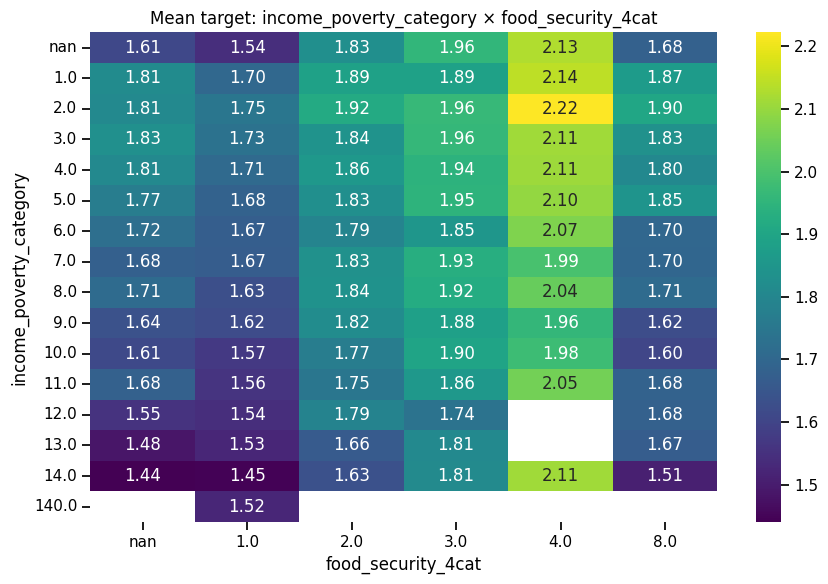

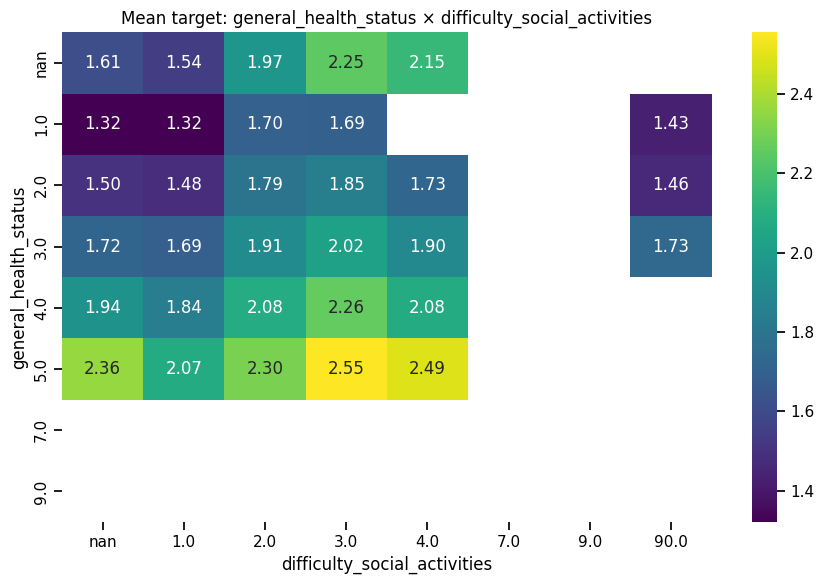

In [15]:
def interaction_heatmap(df,row_feature,col_feature,min_count=50):
    if row_feature not in df or col_feature not in df:
        return
    g=df.groupby([row_feature,col_feature],dropna=False)[CFG.TARGET].agg(["mean","count"]).reset_index()
    g.loc[g["count"]<min_count,"mean"]=np.nan
    pivot=g.pivot(index=row_feature,columns=col_feature,values="mean")
    plt.figure(figsize=(9,6)); sns.heatmap(pivot,annot=True,fmt=".2f",cmap="viridis")
    plt.title(f"Mean target: {row_feature} × {col_feature}"); plt.tight_layout(); plt.show()

for a,b in [
    ("general_health_status","depression_frequency"),
    ("depression_frequency","anxiety_frequency"),
    ("income_poverty_category","food_security_4cat"),
    ("general_health_status","difficulty_social_activities"),
]:
    interaction_heatmap(train,a,b)


## 5. Feature Engineering


### V2 feature-engineering policy by requested category

- **Discretization:** only conservative `age_band`; trees keep the raw continuous values too.
- **Feature Selection:** nested grouped inner split inside every outer fold; no outer-validation feature-selection leakage.
- **Feature Creation:** domain burden counts, missingness/repair counts, semantic-code indicators, and a very small interaction bank.
- **Clipping / outliers:** no blind winsorization or row dropping. Survey sentinel/nonstandard values are represented semantically while the raw code is preserved.
- **Feature Encoding:** raw numeric view + dictionary-valid semantic view + native categorical copies for selected nominal fields.

This follows the V1 finding that adding more arbitrary features does not automatically improve QWK.

In [16]:
FUNCTIONAL_DIFFICULTY_COLS = [
    "difficulty_walking_steps","difficulty_walking_short","difficulty_walking_medium","difficulty_climbing_steps",
    "difficulty_using_hands","difficulty_raising_arm","difficulty_self_care","difficulty_communicating",
    "difficulty_remembering","difficulty_errands_alone","difficulty_social_activities",
]
CHRONIC_CONDITION_COLS = [
    "hypertension_ever","high_cholesterol_ever","heart_disease_ever","heart_attack_ever","angina_ever","stroke_ever",
    "asthma_ever","diabetes_ever","prediabetes_ever","cancer_ever","lung_disease_ever","arthritis_ever","dementia_ever","chronic_fatigue_ever",
]
COST_BARRIER_YES_COLS = [
    "trouble_paying_medical_bills","delayed_care_due_to_cost","skipped_care_due_to_cost",
    "skipped_medication_to_save_money","took_less_medication_to_save_money","delayed_prescription_to_save_money",
    "skipped_prescription_due_to_cost","delayed_therapy_due_to_cost","skipped_therapy_due_to_cost",
]
INCOME_SOURCE_COLS = ["has_wage_income","has_investment_income","has_social_security_income","has_disability_income","has_public_assistance_income","has_retirement_income","has_other_income"]
INSURANCE_YES_COLS = ["has_health_insurance","has_private_insurance","has_senior_gov_insurance","has_lowincome_gov_insurance","has_child_gov_insurance","has_military_insurance","has_state_health_plan","has_other_gov_insurance"]
FREQUENCY_COLS=[CFG.HOUSEHOLD_COL,"pseudo_stratum","pseudo_psu"]

# Conservative nominal list: these are not treated as ordinal just because their source codes are integers.
NATIVE_NOMINAL_COLS = [
    "record_type","survey_year","geographic_region","pseudo_stratum","pseudo_psu","sex","citizenship_status","born_in_country",
    "sexual_orientation","parental_status","relationship_to_child","marital_status","legal_marital_status","marital_status_detailed",
    "health_insurance_type","insurance_source_plan1","type_of_care_provider","home_ownership","smoking_status","ecigarette_status",
    "interview_quarter","interview_month",
]


def count_yes(df,cols):
    cols=[c for c in cols if c in df]
    return (df[cols]==1).sum(axis=1).astype(np.int16) if cols else pd.Series(0,index=df.index,dtype=np.int16)


def reverse_ordinal(series,max_valid):
    s=pd.to_numeric(series,errors="coerce")
    out=pd.Series(np.nan,index=s.index,dtype=float)
    valid=s.between(1,max_valid)
    out.loc[valid]=(max_valid+1)-s.loc[valid]
    return out


class SemanticFeatureEngineer:
    def __init__(self, valid_code_map):
        self.valid_code_map=valid_code_map
        self.frequency_maps_={}
        self.engineered_feature_names_=[]
        self.semantic_cols_=[]

    def fit(self,df):
        for c in FREQUENCY_COLS:
            if c in df:
                self.frequency_maps_[c]=df[c].value_counts(dropna=False).to_dict()
        return self

    def transform(self,df):
        out=df.copy(); before=set(out.columns)

        # Fold-safe frequency encoding only; household raw ID is later dropped.
        for c,mapping in self.frequency_maps_.items():
            if c in out:
                out[f"{c}__frequency"]=out[c].map(mapping).fillna(0).astype(np.float32)
                out[f"{c}__log_frequency"]=np.log1p(out[f"{c}__frequency"]).astype(np.float32)

        # V2 dual semantic representation for undocumented survey codes.
        semantic_cols=[]; nonstd_cols=[]
        for c in SEMANTIC_CODE_COLS:
            if c not in out or c not in self.valid_code_map:
                continue
            raw=pd.to_numeric(out[c],errors="coerce")
            valid=self.valid_code_map[c]
            sem_name=f"{c}__semantic"; nonstd_name=f"{c}__nonstandard"
            out[sem_name]=raw.where(raw.isin(valid)).astype(np.float32)
            out[nonstd_name]=(raw.notna() & ~raw.isin(valid)).astype(np.int8)
            semantic_cols.append(sem_name); nonstd_cols.append(nonstd_name)
        out["nonstandard_code_count"]=out[nonstd_cols].sum(axis=1).astype(np.int16) if nonstd_cols else 0
        self.semantic_cols_=semantic_cols

        # Curated domain burdens from V1.
        out["functional_difficulty_count"]=count_yes(out,FUNCTIONAL_DIFFICULTY_COLS)
        out["chronic_condition_count"]=count_yes(out,CHRONIC_CONDITION_COLS)
        out["cost_barrier_count"]=count_yes(out,COST_BARRIER_YES_COLS)
        out["income_source_count"]=count_yes(out,INCOME_SOURCE_COLS)
        out["insurance_count"]=count_yes(out,INSURANCE_YES_COLS)

        food=[]
        for c in ["worried_food_would_run_out","food_did_not_last","could_not_afford_balanced_meals"]:
            if c in out: food.append(reverse_ordinal(out[c],3).fillna(0))
        out["food_insecurity_count"]=(sum(food).astype(np.float32) if food else 0.0)
        if "received_food_assistance" in out:
            out["food_insecurity_count"] += (out["received_food_assistance"]==1).astype(np.float32)

        if "depression_frequency" in out:
            out["depression_burden"]=reverse_ordinal(out["depression_frequency"],5).astype(np.float32)
        if "anxiety_frequency" in out:
            out["anxiety_burden"]=reverse_ordinal(out["anxiety_frequency"],5).astype(np.float32)
        mental=[]
        for c in ["depression_burden","anxiety_burden"]:
            if c in out: mental.append(out[c].fillna(0))
        out["mental_frequency_burden"]=(sum(mental).astype(np.float32) if mental else 0.0)

        hh=[]
        for c in ["children_in_household","adults_in_household"]:
            if c in out: hh.append(pd.to_numeric(out[c],errors="coerce").fillna(0))
        out["household_size_proxy"]=(sum(hh).astype(np.float32) if hh else 0.0)

        # Conservative discretization only.
        if "age" in out:
            age=pd.to_numeric(out["age"],errors="coerce").where(pd.to_numeric(out["age"],errors="coerce").between(18,85))
            out["age_band"]=pd.cut(age,bins=[17,24,34,44,54,64,74,85],labels=False,include_lowest=True).astype(float)

        # Small semantic interaction bank: depth shortcuts, not feature explosion.
        def valid_product(a,b,name):
            if a in out and b in out:
                out[name]=(pd.to_numeric(out[a],errors="coerce")*pd.to_numeric(out[b],errors="coerce")).astype(np.float32)
        valid_product("general_health_status__semantic","depression_burden","health_x_depression_burden")
        valid_product("general_health_status__semantic","anxiety_burden","health_x_anxiety_burden")
        valid_product("income_poverty_category__semantic","food_security_4cat__semantic","poverty_x_food_security")
        valid_product("mental_frequency_burden","functional_difficulty_count","mental_x_functional_burden")

        # Never expose respondent/household identity to boosters.
        out=out.drop(columns=[c for c in [CFG.ID_COL,CFG.HOUSEHOLD_COL] if c in out],errors="ignore")
        self.engineered_feature_names_=[c for c in out.columns if c not in before]
        return out

    def fit_transform(self,df):
        return self.fit(df).transform(df)


### 5.1 Mandatory semantic/domain anchors


In [17]:
DOMAIN_FORCE_KEEP=[
    "general_health_status","general_health_status__semantic",
    "depression_frequency","depression_frequency__semantic","depression_burden",
    "anxiety_frequency","anxiety_frequency__semantic","anxiety_burden","anxiety_level",
    "income_to_poverty_ratio","income_poverty_category","income_poverty_category__semantic",
    "food_security_4cat","food_security_4cat__semantic","food_security_3cat",
    "difficulty_social_activities","difficulty_remembering","marital_status","marital_status_detailed",
    "age","survey_weight","row_missing_count_raw","row_missing_count_after_repair","repaired_value_count",
    "special_code_count","nonstandard_code_count","functional_difficulty_count","chronic_condition_count",
    "cost_barrier_count","food_insecurity_count","income_source_count","insurance_count","household_size_proxy",
    "mental_frequency_burden","health_x_depression_burden","health_x_anxiety_burden","poverty_x_food_security","mental_x_functional_burden",
]


### 5.2 Nested fold-safe feature selection


In [18]:
def make_lgb_fs(seed, use_gpu=True):
    params=dict(
        objective="regression_l2",n_estimators=CFG.INNER_FS_ESTIMATORS,learning_rate=0.035,
        num_leaves=31,min_child_samples=40,colsample_bytree=0.9,subsample=0.9,subsample_freq=1,
        reg_lambda=4.0,random_state=seed,n_jobs=-1,verbosity=-1,
    )
    if use_gpu: params.update(device_type="gpu",max_bin=63)
    return lgb.LGBMRegressor(**params)


def nested_select_features(X_outer_train,y_outer_train,groups_outer_train,engineered_names,seed):
    y_outer_train=np.asarray(y_outer_train)
    inner_strata=pd.Series(y_outer_train).astype(str).values
    inner_cv=StratifiedGroupKFold(n_splits=CFG.INNER_N_FOLDS,shuffle=True,random_state=seed)
    i_tr,i_va=next(inner_cv.split(X_outer_train,inner_strata,groups=groups_outer_train))
    all_features=X_outer_train.columns.tolist()

    model=None
    for gpu_flag in ([True,False] if CFG.USE_GPU else [False]):
        try:
            model=make_lgb_fs(seed,use_gpu=gpu_flag)
            model.fit(X_outer_train.iloc[i_tr],y_outer_train[i_tr],eval_set=[(X_outer_train.iloc[i_va],y_outer_train[i_va])],
                      callbacks=[lgb.early_stopping(CFG.INNER_FS_EARLY_STOPPING,verbose=False)])
            break
        except Exception as e:
            if gpu_flag:
                print("Inner FS LightGBM GPU fallback:",repr(e)); gc.collect(); continue
            raise

    gain=model.booster_.feature_importance(importance_type="gain")
    ranked=[f for _,f in sorted(zip(gain,all_features),reverse=True)]
    mandatory=[c for c in DOMAIN_FORCE_KEEP if c in X_outer_train]
    mandatory += [c for c in engineered_names if c in X_outer_train]
    mandatory += [c for c in X_outer_train if c.endswith("__nonstandard") or c.endswith("__special_code")]
    selected=list(dict.fromkeys(ranked[:CFG.INNER_TOP_N]+mandatory))
    return selected, pd.DataFrame({"feature":all_features,"gain":gain}).sort_values("gain",ascending=False)


## 6. Modeling — Core + Representation/Objectives Diversity


### 6.1 Branch preparation helpers


In [19]:
def prepare_catboost_frame(X,features):
    Xc=X[features].copy()
    cat_cols=[c for c in NATIVE_NOMINAL_COLS if c in Xc]
    for c in cat_cols:
        Xc[c]=Xc[c].map(lambda v:"__MISSING__" if pd.isna(v) else str(v))
    return Xc,cat_cols


def prepare_native_categorical_views(X_tr,X_va,X_te,features):
    A=X_tr[features].copy(); B=X_va[features].copy(); C=X_te[features].copy()
    cat_cols=[]
    for c in NATIVE_NOMINAL_COLS:
        if c not in A:
            continue
        source=f"{c}__semantic" if f"{c}__semantic" in A else c
        if source not in A:
            continue
        new=f"{c}__cat"
        combined=pd.concat([A[source],B[source],C[source]],axis=0)
        levels=pd.Index(combined.dropna().astype(str).unique())
        for frame,src in [(A,source),(B,source),(C,source)]:
            vals=frame[src].map(lambda v:"__MISSING__" if pd.isna(v) else str(v))
            frame[new]=pd.Categorical(vals,categories=list(levels)+(["__MISSING__"] if "__MISSING__" not in levels else []))
        cat_cols.append(new)
    return A,B,C,cat_cols


def monotone_constraint_vector(features):
    direction={
        "general_health_status__semantic":+1,
        "depression_burden":+1,
        "anxiety_burden":+1,
        "mental_frequency_burden":+1,
        "functional_difficulty_count":+1,
        "food_insecurity_count":+1,
        "cost_barrier_count":+1,
        "income_to_poverty_ratio":-1,
        "income_poverty_category__semantic":-1,
        "food_security_4cat__semantic":+1,
        "worry_about_medical_costs__semantic":-1,
    }
    return [int(direction.get(c,0)) for c in features]


### 6.2 Model factories with GPU fallback


In [20]:
def make_lgb_reg(seed,use_gpu=True,monotone_constraints=None):
    params=dict(
        objective="regression_l2",n_estimators=CFG.LGB_N_ESTIMATORS,learning_rate=CFG.LEARNING_RATE,
        num_leaves=31,min_child_samples=40,max_depth=-1,subsample=0.85,subsample_freq=1,colsample_bytree=0.85,
        reg_alpha=0.05,reg_lambda=4.0,random_state=seed,n_jobs=-1,verbosity=-1,
    )
    if monotone_constraints is not None:
        params["monotone_constraints"]=monotone_constraints
        params["monotone_constraints_method"]="advanced"
    if use_gpu: params.update(device_type="gpu",max_bin=63)
    return lgb.LGBMRegressor(**params)


def make_lgb_classifier(seed,objective="multiclass",use_gpu=True):
    params=dict(
        n_estimators=CFG.LGB_N_ESTIMATORS,learning_rate=CFG.LEARNING_RATE,num_leaves=31,min_child_samples=40,
        subsample=0.85,subsample_freq=1,colsample_bytree=0.85,reg_lambda=4.0,random_state=seed,n_jobs=-1,verbosity=-1,
    )
    if objective=="multiclass": params.update(objective="multiclass",num_class=4)
    else: params.update(objective="binary")
    if use_gpu: params.update(device_type="gpu",max_bin=63)
    return lgb.LGBMClassifier(**params)


def make_xgb_reg(seed,use_gpu=True,enable_categorical=False):
    params=dict(
        objective="reg:squarederror",eval_metric="rmse",n_estimators=CFG.XGB_N_ESTIMATORS,learning_rate=CFG.LEARNING_RATE,
        max_depth=6,min_child_weight=8,subsample=0.85,colsample_bytree=0.85,reg_alpha=0.05,reg_lambda=4.0,
        tree_method="hist",random_state=seed,n_jobs=-1,early_stopping_rounds=CFG.EARLY_STOPPING,
        enable_categorical=enable_categorical,
    )
    if enable_categorical:
        params["max_cat_to_onehot"]=4
        params["max_cat_threshold"]=64
    if use_gpu: params["device"]="cuda"
    return xgb.XGBRegressor(**params)


def make_cat(seed,use_gpu=True):
    params=dict(
        loss_function="RMSE",eval_metric="RMSE",iterations=CFG.CAT_ITERATIONS,learning_rate=CFG.LEARNING_RATE,depth=7,
        l2_leaf_reg=6.0,random_strength=0.5,random_seed=seed,od_type="Iter",od_wait=CFG.EARLY_STOPPING,
        allow_writing_files=False,verbose=CFG.VERBOSE,
    )
    if use_gpu: params.update(task_type="GPU",devices=CFG.CAT_DEVICES)
    else: params.update(task_type="CPU",thread_count=-1)
    return CatBoostRegressor(**params)


def fit_lgb_reg(Xtr,ytr,Xva,yva,Xte,seed,monotone=None,categorical_feature=None):
    for gpu in ([True,False] if CFG.USE_GPU else [False]):
        try:
            m=make_lgb_reg(seed,gpu,monotone)
            m.fit(Xtr,ytr,eval_set=[(Xva,yva)],eval_metric="rmse",categorical_feature=categorical_feature,
                  callbacks=[lgb.early_stopping(CFG.EARLY_STOPPING,verbose=False),lgb.log_evaluation(CFG.VERBOSE)])
            return m,m.predict(Xva,num_iteration=m.best_iteration_),m.predict(Xte,num_iteration=m.best_iteration_)
        except Exception as e:
            if gpu:
                print("LightGBM GPU -> CPU fallback:",repr(e)); gc.collect(); continue
            raise


def fit_xgb_reg(Xtr,ytr,Xva,yva,Xte,seed,enable_categorical=False):
    for gpu in ([True,False] if CFG.USE_GPU else [False]):
        try:
            m=make_xgb_reg(seed,gpu,enable_categorical)
            m.fit(Xtr,ytr,eval_set=[(Xva,yva)],verbose=False)
            return m,m.predict(Xva),m.predict(Xte)
        except Exception as e:
            if gpu:
                print("XGBoost CUDA -> CPU fallback:",repr(e)); gc.collect(); continue
            raise


def fit_cat(Xtr,ytr,Xva,yva,Xte,cat_cols,seed):
    for gpu in ([True,False] if CFG.USE_GPU else [False]):
        try:
            m=make_cat(seed,gpu)
            m.fit(Xtr,ytr,eval_set=(Xva,yva),cat_features=cat_cols,use_best_model=True)
            return m,m.predict(Xva),m.predict(Xte)
        except Exception as e:
            if gpu:
                print("CatBoost GPU -> CPU fallback:",repr(e)); gc.collect(); continue
            raise


def fit_lgb_multiclass_expected(Xtr,ytr,Xva,yva,Xte,seed):
    y0=np.asarray(ytr)-1; yv0=np.asarray(yva)-1
    for gpu in ([True,False] if CFG.USE_GPU else [False]):
        try:
            m=make_lgb_classifier(seed,"multiclass",gpu)
            m.fit(Xtr,y0,eval_set=[(Xva,yv0)],eval_metric="multi_logloss",
                  callbacks=[lgb.early_stopping(CFG.EARLY_STOPPING,verbose=False),lgb.log_evaluation(CFG.VERBOSE)])
            pv=m.predict_proba(Xva,num_iteration=m.best_iteration_)
            pt=m.predict_proba(Xte,num_iteration=m.best_iteration_)
            classes=np.arange(1,5,dtype=float)
            return m,pv@classes,pt@classes
        except Exception as e:
            if gpu:
                print("LGB multiclass GPU -> CPU fallback:",repr(e)); gc.collect(); continue
            raise


def fit_lgb_cumulative_ordinal(Xtr,ytr,Xva,yva,Xte,seed):
    pva=[]; pte=[]; models=[]
    for boundary in [1,2,3]:
        yt=(np.asarray(ytr)>boundary).astype(int); yv=(np.asarray(yva)>boundary).astype(int)
        fitted=None
        for gpu in ([True,False] if CFG.USE_GPU else [False]):
            try:
                m=make_lgb_classifier(seed+boundary*101,"binary",gpu)
                m.fit(Xtr,yt,eval_set=[(Xva,yv)],eval_metric="binary_logloss",
                      callbacks=[lgb.early_stopping(CFG.EARLY_STOPPING,verbose=False)])
                pva.append(m.predict_proba(Xva,num_iteration=m.best_iteration_)[:,1])
                pte.append(m.predict_proba(Xte,num_iteration=m.best_iteration_)[:,1])
                models.append(m); fitted=True; break
            except Exception as e:
                if gpu:
                    print(f"Ordinal boundary {boundary} GPU -> CPU fallback:",repr(e)); gc.collect(); continue
                raise
        assert fitted
    pva=np.column_stack(pva); pte=np.column_stack(pte)
    # Enforce cumulative consistency P(y>1)>=P(y>2)>=P(y>3).
    pva[:,1]=np.minimum(pva[:,1],pva[:,0]); pva[:,2]=np.minimum(pva[:,2],pva[:,1])
    pte[:,1]=np.minimum(pte[:,1],pte[:,0]); pte[:,2]=np.minimum(pte[:,2],pte[:,1])
    return models,1.0+pva.sum(axis=1),1.0+pte.sum(axis=1)


### 6.3 2×5 repeated outer CV


In [21]:
branch_names=["lgb_core","xgb_core","cat_core"]
if CFG.RUN_LGB_CATEGORICAL: branch_names.append("lgb_categorical")
if CFG.RUN_XGB_CATEGORICAL: branch_names.append("xgb_categorical")
if CFG.RUN_MONOTONIC: branch_names.append("lgb_monotonic")
if CFG.RUN_MULTICLASS: branch_names.append("lgb_multiclass_expected")
if CFG.RUN_ORDINAL: branch_names.append("lgb_cumulative_ordinal")

OOF_SUM={b:np.zeros(len(train),dtype=np.float64) for b in branch_names}
OOF_COUNT={b:np.zeros(len(train),dtype=np.int8) for b in branch_names}
TEST_SUM={b:np.zeros(len(test),dtype=np.float64) for b in branch_names}
branch_failures=defaultdict(list)
fold_metric_rows=[]
feature_selection_rows=[]
feature_importance_rows=[]
primary_fold_id=np.full(len(train),-1,dtype=np.int8)

for repeat,fold,seed,tr_idx,va_idx in repeated_folds:
    print("\n"+"="*90)
    print(f"REPEAT {repeat+1}/{CFG.N_REPEATS} | FOLD {fold+1}/{CFG.N_FOLDS} | seed={seed}")
    print("="*90)
    if repeat==0: primary_fold_id[va_idx]=fold

    raw_tr=train.iloc[tr_idx].copy(); raw_va=train.iloc[va_idx].copy(); raw_te=test.copy()
    ytr=y[tr_idx]; yva=y[va_idx]; gtr=groups[tr_idx]

    # Fold-safe preprocessing and semantic FE.
    pre=FoldPreprocessor(CFG.REPAIR_MIN_ACCURACY,CFG.REPAIR_MIN_SUPPORT).fit(raw_tr)
    ptr=pre.transform(raw_tr); pva=pre.transform(raw_va); pte=pre.transform(raw_te)
    fe=SemanticFeatureEngineer(DICT_VALID_CODES).fit(ptr)
    Xtr=fe.transform(ptr); Xva=fe.transform(pva); Xte=fe.transform(pte)

    assert Xtr.columns.tolist()==Xva.columns.tolist()==Xte.columns.tolist()
    selected,fs_imp=nested_select_features(Xtr,ytr,gtr,fe.engineered_feature_names_,seed+fold*31)
    feature_selection_rows.append({"repeat":repeat,"fold":fold,"selected_count":len(selected),"selected_features":"|".join(selected)})

    A=Xtr[selected].copy(); B=Xva[selected].copy(); C=Xte[selected].copy()
    model_seed=seed+fold*997

    # --- Core LightGBM regression ---
    m,pv,pt=fit_lgb_reg(A,ytr,B,yva,C,model_seed)
    OOF_SUM["lgb_core"][va_idx]+=pv; OOF_COUNT["lgb_core"][va_idx]+=1; TEST_SUM["lgb_core"]+=pt
    for f,imp in zip(selected,m.booster_.feature_importance(importance_type="gain")):
        feature_importance_rows.append({"repeat":repeat,"fold":fold,"branch":"lgb_core","feature":f,"importance":float(imp)})

    # --- Core XGBoost regression ---
    m,pv,pt=fit_xgb_reg(A,ytr,B,yva,C,model_seed+11,False)
    OOF_SUM["xgb_core"][va_idx]+=pv; OOF_COUNT["xgb_core"][va_idx]+=1; TEST_SUM["xgb_core"]+=pt
    for f,imp in zip(selected,m.feature_importances_):
        feature_importance_rows.append({"repeat":repeat,"fold":fold,"branch":"xgb_core","feature":f,"importance":float(imp)})

    # --- Core CatBoost regression ---
    Act,cat_cols=prepare_catboost_frame(Xtr,selected); Bct,_=prepare_catboost_frame(Xva,selected); Cct,_=prepare_catboost_frame(Xte,selected)
    m,pv,pt=fit_cat(Act,ytr,Bct,yva,Cct,cat_cols,model_seed+23)
    OOF_SUM["cat_core"][va_idx]+=pv; OOF_COUNT["cat_core"][va_idx]+=1; TEST_SUM["cat_core"]+=pt
    for f,imp in zip(selected,m.get_feature_importance()):
        feature_importance_rows.append({"repeat":repeat,"fold":fold,"branch":"cat_core","feature":f,"importance":float(imp)})

    # --- Native categorical branches ---
    if CFG.RUN_LGB_CATEGORICAL or CFG.RUN_XGB_CATEGORICAL:
        Ac,Bc,Cc,native_cat_cols=prepare_native_categorical_views(Xtr,Xva,Xte,selected)
        native_features=Ac.columns.tolist()

        if CFG.RUN_LGB_CATEGORICAL:
            try:
                m,pv,pt=fit_lgb_reg(Ac,ytr,Bc,yva,Cc,model_seed+37,categorical_feature=native_cat_cols)
                OOF_SUM["lgb_categorical"][va_idx]+=pv; OOF_COUNT["lgb_categorical"][va_idx]+=1; TEST_SUM["lgb_categorical"]+=pt
            except Exception as e:
                branch_failures["lgb_categorical"].append((repeat,fold,repr(e))); print("SKIP lgb_categorical fold:",repr(e))

        if CFG.RUN_XGB_CATEGORICAL:
            try:
                m,pv,pt=fit_xgb_reg(Ac,ytr,Bc,yva,Cc,model_seed+41,True)
                OOF_SUM["xgb_categorical"][va_idx]+=pv; OOF_COUNT["xgb_categorical"][va_idx]+=1; TEST_SUM["xgb_categorical"]+=pt
            except Exception as e:
                branch_failures["xgb_categorical"].append((repeat,fold,repr(e))); print("SKIP xgb_categorical fold:",repr(e))

    # --- Monotonic semantic branch ---
    if CFG.RUN_MONOTONIC:
        try:
            mono=monotone_constraint_vector(selected)
            m,pv,pt=fit_lgb_reg(A,ytr,B,yva,C,model_seed+53,monotone=mono)
            OOF_SUM["lgb_monotonic"][va_idx]+=pv; OOF_COUNT["lgb_monotonic"][va_idx]+=1; TEST_SUM["lgb_monotonic"]+=pt
        except Exception as e:
            branch_failures["lgb_monotonic"].append((repeat,fold,repr(e))); print("SKIP lgb_monotonic fold:",repr(e))

    # --- Objective diversity sidecars ---
    if CFG.RUN_MULTICLASS:
        try:
            m,pv,pt=fit_lgb_multiclass_expected(A,ytr,B,yva,C,model_seed+67)
            OOF_SUM["lgb_multiclass_expected"][va_idx]+=pv; OOF_COUNT["lgb_multiclass_expected"][va_idx]+=1; TEST_SUM["lgb_multiclass_expected"]+=pt
        except Exception as e:
            branch_failures["lgb_multiclass_expected"].append((repeat,fold,repr(e))); print("SKIP multiclass fold:",repr(e))

    if CFG.RUN_ORDINAL:
        try:
            _,pv,pt=fit_lgb_cumulative_ordinal(A,ytr,B,yva,C,model_seed+79)
            OOF_SUM["lgb_cumulative_ordinal"][va_idx]+=pv; OOF_COUNT["lgb_cumulative_ordinal"][va_idx]+=1; TEST_SUM["lgb_cumulative_ordinal"]+=pt
        except Exception as e:
            branch_failures["lgb_cumulative_ordinal"].append((repeat,fold,repr(e))); print("SKIP ordinal fold:",repr(e))

    gc.collect()

assert (primary_fold_id>=0).all()
print("\nBranch failures:")
for b,items in branch_failures.items(): print(b,len(items),items[:2])



REPEAT 1/2 | FOLD 1/5 | seed=42


1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.


[400]	valid_0's rmse: 0.513473	valid_0's l2: 0.263655
[800]	valid_0's rmse: 0.513107	valid_0's l2: 0.263279
0:	learn: 0.6040883	test: 0.6053521	best: 0.6053521 (0)	total: 131ms	remaining: 11m 59s
400:	learn: 0.5099269	test: 0.5148800	best: 0.5148800 (400)	total: 9.71s	remaining: 2m 3s
800:	learn: 0.5025050	test: 0.5139055	best: 0.5139044 (799)	total: 19.4s	remaining: 1m 53s
1200:	learn: 0.4962828	test: 0.5135761	best: 0.5135730 (1193)	total: 29.1s	remaining: 1m 44s
1600:	learn: 0.4904851	test: 0.5134618	best: 0.5134574 (1586)	total: 39s	remaining: 1m 34s
2000:	learn: 0.4848819	test: 0.5133693	best: 0.5133353 (1954)	total: 48.8s	remaining: 1m 25s
bestTest = 0.51333526
bestIteration = 1954
Shrink model to first 1955 iterations.


1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.


[400]	valid_0's rmse: 0.516332	valid_0's l2: 0.266599
[400]	valid_0's rmse: 0.51371	valid_0's l2: 0.263898
[800]	valid_0's rmse: 0.513459	valid_0's l2: 0.263641


1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.


[400]	valid_0's multi_logloss: 0.700103

REPEAT 1/2 | FOLD 2/5 | seed=42
[400]	valid_0's rmse: 0.515073	valid_0's l2: 0.265301
[800]	valid_0's rmse: 0.515167	valid_0's l2: 0.265397
0:	learn: 0.6049573	test: 0.6015413	best: 0.6015413 (0)	total: 33.5ms	remaining: 3m 4s
400:	learn: 0.5093423	test: 0.5164240	best: 0.5164240 (400)	total: 9.55s	remaining: 2m 1s
800:	learn: 0.5016813	test: 0.5154281	best: 0.5154225 (797)	total: 18.9s	remaining: 1m 50s
1200:	learn: 0.4951903	test: 0.5150100	best: 0.5149989 (1195)	total: 28.2s	remaining: 1m 40s
1600:	learn: 0.4892885	test: 0.5148578	best: 0.5148538 (1595)	total: 37.7s	remaining: 1m 31s
bestTest = 0.5148417018
bestIteration = 1686
Shrink model to first 1687 iterations.
[400]	valid_0's rmse: 0.516905	valid_0's l2: 0.26719
[400]	valid_0's rmse: 0.515303	valid_0's l2: 0.265537
[400]	valid_0's multi_logloss: 0.703917

REPEAT 1/2 | FOLD 3/5 | seed=42
[400]	valid_0's rmse: 0.520617	valid_0's l2: 0.271042
0:	learn: 0.6035113	test: 0.6073067	best: 0.607

## 7. Evaluation — OOF Reliability, Diversity, and Greedy Blend Selection


In [22]:
# Keep only branches that produced exactly one OOF prediction per repeat for every row.
valid_branches=[]; oof_cont={}; test_cont={}
for b in branch_names:
    complete=np.all(OOF_COUNT[b]==CFG.N_REPEATS)
    if complete:
        valid_branches.append(b)
        oof_cont[b]=OOF_SUM[b]/CFG.N_REPEATS
        test_cont[b]=TEST_SUM[b]/(CFG.N_REPEATS*CFG.N_FOLDS)
    else:
        print(f"Dropping incomplete branch {b}: OOF count range {OOF_COUNT[b].min()}..{OOF_COUNT[b].max()}")

print("Valid complete branches:",valid_branches)
assert all(x in valid_branches for x in ["lgb_core","xgb_core","cat_core"])


def crossfit_threshold_score(y_true,pred,fold_ids):
    y_true=np.asarray(y_true); pred=np.asarray(pred); fold_ids=np.asarray(fold_ids)
    labels=np.zeros(len(y_true),dtype=int); thresholds={}
    for f in sorted(np.unique(fold_ids)):
        tr=fold_ids!=f; va=fold_ids==f
        t,_=optimize_thresholds(y_true[tr],pred[tr],maxiter=130)
        labels[va]=apply_thresholds(pred[va],t); thresholds[int(f)]=t
    return qwk(y_true,labels),labels,thresholds

branch_eval=[]
for b in valid_branches:
    p=oof_cont[b]
    t,g=optimize_thresholds(y,p)
    cf,lab,cft=crossfit_threshold_score(y,p,primary_fold_id)
    auc1=roc_auc_score((y>1).astype(int),p)
    auc2=roc_auc_score((y>2).astype(int),p)
    auc3=roc_auc_score((y>3).astype(int),p)
    branch_eval.append({"branch":b,"rmse":mean_squared_error(y,p)**0.5,"global_qwk":g,"crossfit_qwk":cf,"auc_y_gt_1":auc1,"auc_y_gt_2":auc2,"auc_y_gt_3":auc3,"t1":t[0],"t2":t[1],"t3":t[2]})
branch_eval_df=pd.DataFrame(branch_eval).sort_values("crossfit_qwk",ascending=False)
display(branch_eval_df)


Valid complete branches: ['lgb_core', 'xgb_core', 'cat_core', 'lgb_categorical', 'xgb_categorical', 'lgb_monotonic', 'lgb_multiclass_expected', 'lgb_cumulative_ordinal']


,branch,rmse,global_qwk,crossfit_qwk,auc_y_gt_1,auc_y_gt_2,auc_y_gt_3,t1,t2,t3
2,cat_core,0.515962,0.480533,0.479015,0.779426,0.872001,0.808950,1.559666,2.042826,2.532451
7,lgb_cumulative_ordinal,0.515746,0.480562,0.478750,0.779800,0.871588,0.807577,1.546701,2.007385,2.509301
6,lgb_multiclass_expected,0.516363,0.478961,0.477801,0.779528,0.870336,0.805704,1.566581,1.978279,2.528152
5,lgb_monotonic,0.516002,0.479592,0.477619,0.778880,0.871388,0.808108,1.561425,2.014211,2.623548
1,xgb_core,0.516204,0.479033,0.477523,0.778918,0.871704,0.807740,1.576673,2.020933,2.620232
0,lgb_core,0.515916,0.480071,0.477289,0.779005,0.871822,0.808336,1.556739,2.011160,2.503121
4,xgb_categorical,0.519105,0.474819,0.473704,0.775221,0.868017,0.802907,1.564081,2.006775,2.500054
3,lgb_categorical,0.518220,0.475274,0.473671,0.775873,0.869462,0.804750,1.542420,2.015529,2.565105


### 7.1 Immutable V1-style core reference


In [23]:
core_names=["lgb_core","xgb_core","cat_core"]
core_oof=np.mean(np.column_stack([oof_cont[b] for b in core_names]),axis=1)
core_test=np.mean(np.column_stack([test_cont[b] for b in core_names]),axis=1)
core_t,core_global=optimize_thresholds(y,core_oof)
core_cross,core_cross_labels,core_cross_t=crossfit_threshold_score(y,core_oof,primary_fold_id)
print("V2 repeated-CV core global QWK:",round(core_global,6))
print("V2 repeated-CV core cross-fitted QWK:",round(core_cross,6))
print("Historical V1 cross-fitted OOF:",CFG.V1_CROSSFIT_OOF)


V2 repeated-CV core global QWK: 0.481433
V2 repeated-CV core cross-fitted QWK: 0.480295
Historical V1 cross-fitted OOF: 0.479662


### 7.2 Residual diversity matrix


,lgb_core,xgb_core,cat_core,lgb_categorical,xgb_categorical,lgb_monotonic,lgb_multiclass_expected,lgb_cumulative_ordinal
lgb_core,1.0000,0.9986,0.9968,0.9934,0.9925,0.9990,0.9966,0.9972
xgb_core,0.9986,1.0000,0.9968,0.9929,0.9924,0.9984,0.9962,0.9969
cat_core,0.9968,0.9968,1.0000,0.9919,0.9912,0.9968,0.9954,0.9958
lgb_categorical,0.9934,0.9929,0.9919,1.0000,0.9983,0.9935,0.9917,0.9919
xgb_categorical,0.9925,0.9924,0.9912,0.9983,1.0000,0.9925,0.9910,0.9911
lgb_monotonic,0.9990,0.9984,0.9968,0.9935,0.9925,1.0000,0.9965,0.9971
lgb_multiclass_expected,0.9966,0.9962,0.9954,0.9917,0.9910,0.9965,1.0000,0.9988
lgb_cumulative_ordinal,0.9972,0.9969,0.9958,0.9919,0.9911,0.9971,0.9988,1.0000


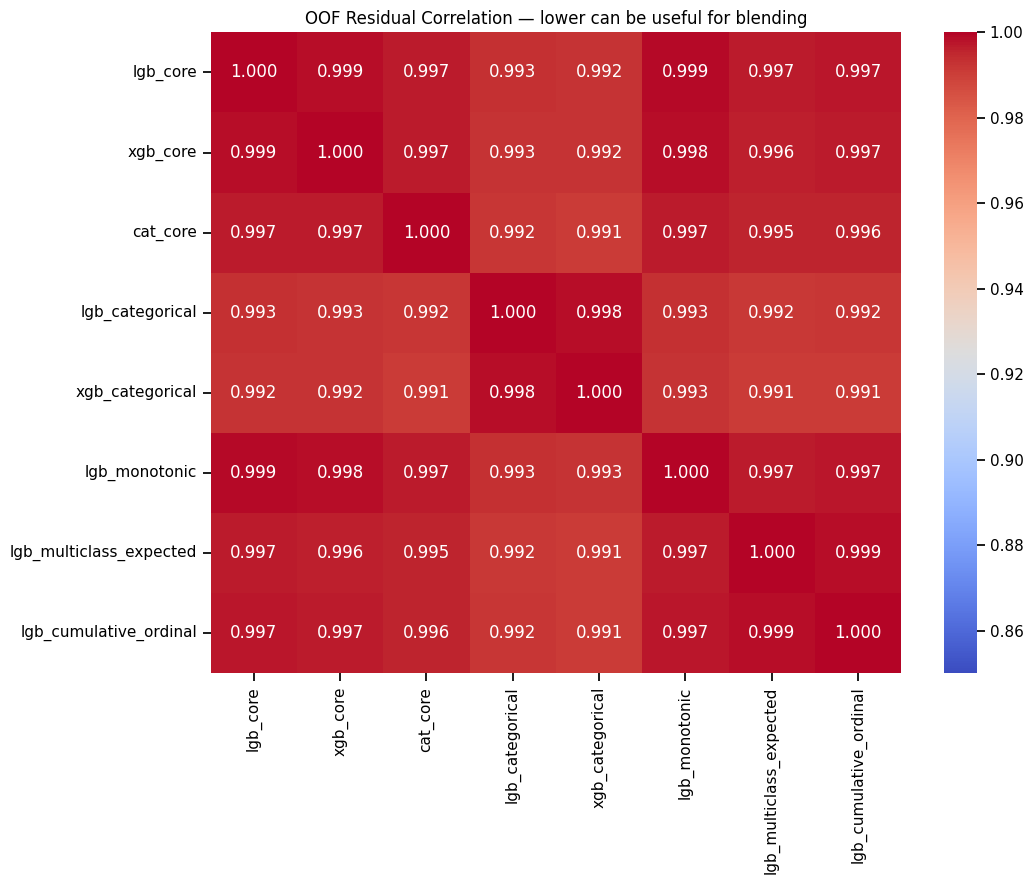

In [24]:
residuals={b:y-oof_cont[b] for b in valid_branches}
resid_corr=pd.DataFrame({b:residuals[b] for b in valid_branches}).corr()
display(resid_corr.style.background_gradient(cmap="coolwarm",vmin=0.85,vmax=1.0).format("{:.4f}"))

plt.figure(figsize=(11,9)); sns.heatmap(resid_corr,annot=True,fmt=".3f",cmap="coolwarm",vmin=0.85,vmax=1.0)
plt.title("OOF Residual Correlation — lower can be useful for blending"); plt.tight_layout(); plt.show()


### 7.3 Greedy OOF blend selection

Start from the proven three-model regression core. A sidecar is admitted only if a small non-negative blend improves **cross-fitted QWK** by at least `MIN_BRANCH_BLEND_GAIN`. This deliberately prevents a high-variance optimizer from inventing tiny gains.


In [25]:
current_oof=core_oof.copy(); current_test=core_test.copy()
current_score=core_cross
selected_steps=[]
remaining=[b for b in valid_branches if b not in core_names]

for step in range(CFG.MAX_SELECTED_SIDECARS):
    best=None
    for b in remaining:
        for alpha in CFG.GREEDY_ALPHA_GRID:
            cand=(1-alpha)*current_oof+alpha*oof_cont[b]
            score,_,_=crossfit_threshold_score(y,cand,primary_fold_id)
            rec={"branch":b,"alpha":float(alpha),"score":float(score),"gain":float(score-current_score),
                 "residual_corr_to_current":float(np.corrcoef(y-current_oof,y-oof_cont[b])[0,1])}
            if best is None or rec["score"]>best["score"]:
                best=rec
    if best is None or best["gain"]<CFG.MIN_BRANCH_BLEND_GAIN:
        print("Stop greedy selection. Best remaining gain:", None if best is None else best["gain"])
        break
    b=best["branch"]; a=best["alpha"]
    current_oof=(1-a)*current_oof+a*oof_cont[b]
    current_test=(1-a)*current_test+a*test_cont[b]
    current_score=best["score"]
    selected_steps.append(best)
    remaining.remove(b)
    print("Accepted:",best)

display(pd.DataFrame(selected_steps))

final_oof_cont=current_oof
final_test_cont_raw=current_test
final_thresholds,final_global_qwk=optimize_thresholds(y,final_oof_cont)
final_cross_qwk,final_cross_labels,final_cross_thresholds=crossfit_threshold_score(y,final_oof_cont,primary_fold_id)
print("Final global OOF QWK:",round(final_global_qwk,6))
print("Final cross-fitted OOF QWK:",round(final_cross_qwk,6))
print("Final thresholds:",np.round(final_thresholds,6))
print("Gain over repeated-CV core:",round(final_cross_qwk-core_cross,6))
print("Gain over historical V1 crossfit:",round(final_cross_qwk-CFG.V1_CROSSFIT_OOF,6))


Accepted: {'branch': 'lgb_multiclass_expected', 'alpha': 0.35, 'score': 0.4813768382093312, 'gain': 0.0010823263086139345, 'residual_corr_to_current': 0.9969030083016587}
Accepted: {'branch': 'lgb_cumulative_ordinal', 'alpha': 0.05, 'score': 0.4817162466360553, 'gain': 0.000339408426724086, 'residual_corr_to_current': 0.9986547897857201}
Stop greedy selection. Best remaining gain: -0.0004938118463103658


,branch,alpha,score,gain,residual_corr_to_current
0,lgb_multiclass_expected,0.35,0.481377,0.001082,0.996903
1,lgb_cumulative_ordinal,0.05,0.481716,0.000339,0.998655


Final global OOF QWK: 0.48201
Final cross-fitted OOF QWK: 0.481716
Final thresholds: [1.562662 1.998743 2.55253 ]
Gain over repeated-CV core: 0.001422
Gain over historical V1 crossfit: 0.002054


### 7.4 Boundary / confusion analysis


In [26]:
final_oof_class=apply_thresholds(final_oof_cont,final_thresholds)
conf=pd.crosstab(pd.Series(y,name="actual"),pd.Series(final_cross_labels,name="crossfit_prediction"),normalize="index")
display(conf.style.format("{:.1%}"))

boundary_rows=[]
for k in [1,2,3]:
    boundary_rows.append({"boundary":f"y>{k}","auc":roc_auc_score((y>k).astype(int),final_oof_cont)})
display(pd.DataFrame(boundary_rows))

mean_by_class=pd.DataFrame({"y":y,"score":final_oof_cont}).groupby("y").score.agg(["mean","std","median"])
display(mean_by_class)


crossfit_prediction,1,2,3,4
actual,,,,
1,71.8%,26.3%,1.8%,0.1%
2,32.2%,54.7%,12.2%,0.9%
3,4.8%,32.9%,49.8%,12.5%
4,15.6%,21.1%,36.2%,27.2%


,boundary,auc
0,y>1,0.780005
1,y>2,0.872129
2,y>3,0.808077


,mean,std,median
y,,,
1,1.444680,0.232344,1.412779
2,1.699900,0.278949,1.684715
3,2.113273,0.344052,2.087056
4,2.154519,0.515798,2.193834


### 7.5 OOF vs test distribution sanity check


In [27]:
# Test still contains duplicate raw rows here; distribution sanity is row-level.
print("Continuous KS OOF vs raw test:",ks_2samp(final_oof_cont,final_test_cont_raw).statistic)
qs=[0.01,0.1,0.25,0.5,0.75,0.9,0.99]
display(pd.DataFrame({"q":qs,"oof":np.quantile(final_oof_cont,qs),"test":np.quantile(final_test_cont_raw,qs)}))


Continuous KS OOF vs raw test: 0.00996310236698078


,q,oof,test
0,0.01,1.093847,1.090681
1,0.10,1.231197,1.232706
2,0.25,1.368764,1.375509
3,0.50,1.571469,1.577616
4,0.75,1.786124,1.789086
5,0.90,2.005805,2.009267
6,0.99,2.571942,2.581358


## 8. Final Submission — FIXED Unique-ID Contract


In [28]:
# IMPORTANT: Kaggle evaluator expects one row per UNIQUE test_final.id (23,666),
# not 23,902 raw test rows and not the misleading sample_submission row IDs.
row_level_pred=pd.DataFrame({
    CFG.ID_COL:test[CFG.ID_COL].values,
    "continuous_prediction":final_test_cont_raw,
})

# Exact duplicate raw rows should produce the same prediction. Mean is a safe deterministic aggregation.
dup_spread=row_level_pred.groupby(CFG.ID_COL)["continuous_prediction"].agg(lambda s: float(s.max()-s.min()))
print("Max prediction spread within duplicate test id:",dup_spread.max())

submission_cont=(
    row_level_pred.groupby(CFG.ID_COL,sort=False,as_index=False)["continuous_prediction"].mean()
)
submission_cont[CFG.TARGET]=apply_thresholds(submission_cont["continuous_prediction"].values,final_thresholds).astype(int)
submission=submission_cont[[CFG.ID_COL,CFG.TARGET]].copy()

assert len(submission)==CFG.EXPECTED_UNIQUE_TEST_IDS, len(submission)
assert submission[CFG.ID_COL].is_unique
assert submission[CFG.TARGET].isin([1,2,3,4]).all()
assert submission.isna().sum().sum()==0
# Preserve first-appearance order of unique test ids, exactly like the V1 fixed submission that scored 0.48003.
assert submission[CFG.ID_COL].tolist()==test[CFG.ID_COL].drop_duplicates().tolist()

display(submission.head(10))
print("Submission rows:",len(submission))
print(submission[CFG.TARGET].value_counts(normalize=True).sort_index())

submission_path=CFG.OUTPUT_DIR/"submission_v2.csv"
submission.to_csv(submission_path,index=False)
print("Saved:",submission_path)


Max prediction spread within duplicate test id: 0.0


,id,life_satisfaction
0,10373,1
1,27800,2
2,115533,1
3,112254,1
4,10379,1
5,37613,2
6,82491,1
7,78738,1
8,53512,1
9,72128,2


Submission rows: 23666
life_satisfaction
1    0.480647
2    0.415955
3    0.092284
4    0.011113
Name: proportion, dtype: float64
Saved: /kaggle/working/oqdq5_v2/submission_v2.csv


## 9. Save Reproducibility Artifacts


In [29]:
oof_df=pd.DataFrame({CFG.ID_COL:train[CFG.ID_COL].values,CFG.TARGET:y,"primary_fold":primary_fold_id})
for b in valid_branches:
    oof_df[f"oof_{b}_continuous"]=oof_cont[b]
oof_df["oof_core_continuous"]=core_oof
oof_df["oof_final_continuous"]=final_oof_cont
oof_df["oof_final_crossfit_class"]=final_cross_labels

# Row-level test artifacts retain duplicates for reproducibility; submission separately aggregates by id.
test_pred_df=pd.DataFrame({"row_index":np.arange(len(test)),CFG.ID_COL:test[CFG.ID_COL].values})
for b in valid_branches:
    test_pred_df[f"test_{b}_continuous"]=test_cont[b]
test_pred_df["test_core_continuous"]=core_test
test_pred_df["test_final_continuous"]=final_test_cont_raw

feature_selection_df=pd.DataFrame(feature_selection_rows)
feature_importance_df=pd.DataFrame(feature_importance_rows)
fold_audit_df=pd.DataFrame(fold_audit_rows)

summary={
    "version":CFG.VERSION,
    "competition":CFG.COMPETITION_NAME,
    "v1_public_lb_reference":CFG.V1_PUBLIC_LB,
    "v1_crossfit_oof_reference":CFG.V1_CROSSFIT_OOF,
    "current_top1_public_reference":CFG.CURRENT_TOP1_PUBLIC,
    "n_train":len(train),"n_test_raw":len(test),"n_test_unique_id":int(test[CFG.ID_COL].nunique()),
    "n_repeats":CFG.N_REPEATS,"n_folds":CFG.N_FOLDS,
    "valid_branches":valid_branches,
    "core_global_qwk":float(core_global),"core_crossfit_qwk":float(core_cross),
    "final_global_qwk":float(final_global_qwk),"final_crossfit_qwk":float(final_cross_qwk),
    "final_thresholds":[float(x) for x in final_thresholds],
    "selected_sidecars":selected_steps,
    "submission_rows":len(submission),
    "notes":[
        "2x5 repeated StratifiedGroupKFold groups=id",
        "Nested fold-safe feature selection; explainability probe does not control final outer folds",
        "Raw + dictionary-valid semantic + nonstandard survey-code representation",
        "Native categorical LightGBM/XGBoost candidate branches",
        "Monotonic semantic LightGBM diversity branch",
        "Multiclass expected-value and cumulative ordinal sidecars",
        "No scaling, SMOTE, generic imputation, or survey_weight sample weighting",
        "Submission aggregated to one row per unique test_final.id (23,666) before thresholding",
    ],
}

paths={
    "oof":CFG.OUTPUT_DIR/"oof_v2.csv",
    "test_predictions":CFG.OUTPUT_DIR/"test_predictions_v2.csv",
    "branch_evaluation":CFG.OUTPUT_DIR/"branch_evaluation_v2.csv",
    "feature_selection":CFG.OUTPUT_DIR/"feature_selection_v2.csv",
    "feature_importance":CFG.OUTPUT_DIR/"feature_importance_v2.csv",
    "fold_audit":CFG.OUTPUT_DIR/"fold_audit_v2.csv",
    "semantic_audit":CFG.OUTPUT_DIR/"semantic_code_audit_v2.csv",
    "summary":CFG.OUTPUT_DIR/"v2_summary.json",
}

oof_df.to_csv(paths["oof"],index=False)
test_pred_df.to_csv(paths["test_predictions"],index=False)
branch_eval_df.to_csv(paths["branch_evaluation"],index=False)
feature_selection_df.to_csv(paths["feature_selection"],index=False)
feature_importance_df.to_csv(paths["feature_importance"],index=False)
fold_audit_df.to_csv(paths["fold_audit"],index=False)
semantic_audit_df.to_csv(paths["semantic_audit"],index=False)
with open(paths["summary"],"w") as f: json.dump(summary,f,indent=2)

print("Artifacts:")
print(" -",submission_path)
for p in paths.values(): print(" -",p)
display(pd.Series(summary).to_frame("value"))


Artifacts:
 - /kaggle/working/oqdq5_v2/submission_v2.csv
 - /kaggle/working/oqdq5_v2/oof_v2.csv
 - /kaggle/working/oqdq5_v2/test_predictions_v2.csv
 - /kaggle/working/oqdq5_v2/branch_evaluation_v2.csv
 - /kaggle/working/oqdq5_v2/feature_selection_v2.csv
 - /kaggle/working/oqdq5_v2/feature_importance_v2.csv
 - /kaggle/working/oqdq5_v2/fold_audit_v2.csv
 - /kaggle/working/oqdq5_v2/semantic_code_audit_v2.csv
 - /kaggle/working/oqdq5_v2/v2_summary.json


,value
version,v2
competition,Objective Quest DATAQUEST 5.0
v1_public_lb_reference,0.48003
v1_crossfit_oof_reference,0.479662
current_top1_public_reference,0.48853
n_train,95609
n_test_raw,23902
n_test_unique_id,23666
n_repeats,2
n_folds,5


## V2 Decision Rules

Interpret V2 using the **cross-fitted OOF**, not the global threshold score alone:

- `< 0.482`: reject V2 architecture / investigate failed branches.
- `0.482–0.484`: real improvement, but likely not enough to attack #1.
- `0.484–0.486`: worth a leaderboard submission.
- `0.486–0.488`: strong candidate.
- `≥ 0.488`: serious Top-1 attack.

Also inspect:

1. whether gain appears across both repeats, not one lucky fold;
2. whether sidecars lower residual correlation and actually improve the core blend;
3. boundary `y>1` AUC, because class 1↔2 dominated V1's weighted disagreement;
4. OOF/test distribution alignment;
5. final submission **must be exactly 23,666 unique IDs**.



---
# V7 — Foundation Model Breakthrough Stage

The cells above intentionally reproduce the complete V2 pipeline first. V7 treats its final continuous OOF/test prediction as a **frozen anchor**. The stage below does **not** rewrite the anchor based on leaderboard feedback.

Promotion logic:
1. Run fixed grouped probe folds for TabPFN-3 classifier and regressor.
2. A foundation branch is promoted only if it shows genuine ranking/QWK signal on all probe folds.
3. Only promoted branches receive full 5-fold grouped OOF inference.
4. Final combination uses non-negative ridge/NNLS-like continuous stacking. QWK thresholds are learned only after continuous stacking is frozen.
5. A submission is produced, but the notebook clearly marks whether offline evidence supports submitting it.


In [30]:
# V7 dependency install + reproducibility manifest
import os, sys, subprocess, importlib, platform, hashlib, time
from pathlib import Path

V7_OUT = Path('/kaggle/working/oqdq5_v7')
V7_OUT.mkdir(parents=True, exist_ok=True)
V7_CACHE = Path('/kaggle/working/tabpfn_cache')
V7_CACHE.mkdir(parents=True, exist_ok=True)
os.environ['TABPFN_MODEL_CACHE_DIR'] = str(V7_CACHE)
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'max_split_size_mb:512')

# Pinned public package for reproducibility.
TABPFN_PIP_VERSION = '8.5.0'

def ensure_tabpfn():
    try:
        import tabpfn
        ver = getattr(tabpfn, '__version__', 'unknown')
        print('tabpfn already available:', ver)
        if ver != TABPFN_PIP_VERSION:
            print(f'Installing pinned tabpfn=={TABPFN_PIP_VERSION} for reproducibility...')
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', f'tabpfn=={TABPFN_PIP_VERSION}', 'huggingface_hub>=0.24'])
    except Exception:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', f'tabpfn=={TABPFN_PIP_VERSION}', 'huggingface_hub>=0.24'])
    importlib.invalidate_caches()

ensure_tabpfn()

import torch, tabpfn, huggingface_hub
from tabpfn import TabPFNClassifier, TabPFNRegressor
from huggingface_hub import hf_hub_download

print('Python:', sys.version)
print('PyTorch:', torch.__version__)
print('TabPFN:', getattr(tabpfn, '__version__', 'unknown'))
print('HF hub:', huggingface_hub.__version__)
print('CUDA available:', torch.cuda.is_available(), 'GPU count:', torch.cuda.device_count())
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(i, torch.cuda.get_device_name(i))
assert torch.cuda.is_available(), 'V7 foundation stage requires a Kaggle GPU accelerator.'


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 771.2/771.2 kB 7.9 MB/s eta 0:00:00
Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch: 2.10.0+cu128
TabPFN: 8.5.0
HF hub: 1.11.0
CUDA available: True GPU count: 2
0 Tesla T4
1 Tesla T4


In [31]:
# V7 public checkpoint pinning (open, reproducible)
TABPFN_REPO = 'Prior-Labs/tabpfn_3'
TABPFN_REVISION = 'e923ba9be85784206c9e2f43b0035c84d5fd5747'
TABPFN_CLS_FILE = 'tabpfn-v3-classifier-v3_default.ckpt'
TABPFN_REG_FILE = 'tabpfn-v3-regressor-v3_default.ckpt'

print('Downloading/verifying pinned TabPFN-3 checkpoints...')
TABPFN_CLS_PATH = hf_hub_download(
    repo_id=TABPFN_REPO, filename=TABPFN_CLS_FILE,
    revision=TABPFN_REVISION, cache_dir=str(V7_CACHE)
)
TABPFN_REG_PATH = hf_hub_download(
    repo_id=TABPFN_REPO, filename=TABPFN_REG_FILE,
    revision=TABPFN_REVISION, cache_dir=str(V7_CACHE)
)
print('Classifier checkpoint:', TABPFN_CLS_PATH)
print('Regressor checkpoint:', TABPFN_REG_PATH)

def sha256_file(path, chunk=2**20):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        while True:
            b=f.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()

checkpoint_manifest = {
    'repo': TABPFN_REPO,
    'revision': TABPFN_REVISION,
    'classifier_file': TABPFN_CLS_FILE,
    'classifier_sha256': sha256_file(TABPFN_CLS_PATH),
    'regressor_file': TABPFN_REG_FILE,
    'regressor_sha256': sha256_file(TABPFN_REG_PATH),
    'tabpfn_version': getattr(tabpfn,'__version__','unknown'),
}
print(json.dumps(checkpoint_manifest, indent=2))


Downloading/verifying pinned TabPFN-3 checkpoints...


tabpfn-v3-classifier-v3_default.ckpt:   0%|          | 0.00/213M [00:00<?, ?B/s]

tabpfn-v3-regressor-v3_default.ckpt:   0%|          | 0.00/233M [00:00<?, ?B/s]

Classifier checkpoint: /kaggle/working/tabpfn_cache/models--Prior-Labs--tabpfn_3/snapshots/e923ba9be85784206c9e2f43b0035c84d5fd5747/tabpfn-v3-classifier-v3_default.ckpt
Regressor checkpoint: /kaggle/working/tabpfn_cache/models--Prior-Labs--tabpfn_3/snapshots/e923ba9be85784206c9e2f43b0035c84d5fd5747/tabpfn-v3-regressor-v3_default.ckpt
{
  "repo": "Prior-Labs/tabpfn_3",
  "revision": "e923ba9be85784206c9e2f43b0035c84d5fd5747",
  "classifier_file": "tabpfn-v3-classifier-v3_default.ckpt",
  "classifier_sha256": "d0d865d54dfbc524f5703104be90620182dca7e5fb2c16de72e9959ea18f3988",
  "regressor_file": "tabpfn-v3-regressor-v3_default.ckpt",
  "regressor_sha256": "311ce18d97e9533d8585eaadafe040fbdd8070533209ed8696641dadc97a7301",
  "tabpfn_version": "8.5.0"
}


## V7.1 Foundation input view

No external semantic reconstruction is used. The foundation models receive only columns from `train_final/test_final`. `id`, target, and respondent-like household identifier are excluded from modeling. Low-cardinality columns are suggested to TabPFN as categorical; the same raw numeric matrix is used for its regressor. Missing values are preserved.


In [32]:
# Foundation-model feature view: competition data only
V7_EXCLUDE = {CFG.TARGET, CFG.ID_COL, 'household_id'}
V7_FEATURES = [c for c in test.columns if c not in V7_EXCLUDE]

XFM_train_df = train[V7_FEATURES].copy()
XFM_test_df = test[V7_FEATURES].copy()

# Dataset is overwhelmingly numeric-coded. Coerce safely and preserve missingness.
for c in V7_FEATURES:
    XFM_train_df[c] = pd.to_numeric(XFM_train_df[c], errors='coerce')
    XFM_test_df[c] = pd.to_numeric(XFM_test_df[c], errors='coerce')

XFM_train_df = XFM_train_df.replace([np.inf,-np.inf], np.nan).astype(np.float32)
XFM_test_df = XFM_test_df.replace([np.inf,-np.inf], np.nan).astype(np.float32)

# Train-derived categorical suggestion only; no dictionary/external semantic dependency.
V7_CAT_MAX_UNIQUE = 120
V7_CAT_COLS = [c for c in V7_FEATURES if XFM_train_df[c].nunique(dropna=True) <= V7_CAT_MAX_UNIQUE]
V7_CAT_IDX = [V7_FEATURES.index(c) for c in V7_CAT_COLS]

XFM = XFM_train_df.to_numpy(dtype=np.float32, copy=True)
XFM_TEST = XFM_test_df.to_numpy(dtype=np.float32, copy=True)

print('Foundation features:', len(V7_FEATURES))
print('Suggested categorical:', len(V7_CAT_IDX))
print('Train matrix:', XFM.shape, 'Test matrix:', XFM_TEST.shape)
assert XFM.shape[0] == len(train)
assert XFM_TEST.shape[0] == len(test)


Foundation features: 176
Suggested categorical: 173
Train matrix: (95609, 176) Test matrix: (23902, 176)


## V7.2 Fixed grouped breakthrough probe

The probe uses primary grouped folds **0, 2, 3**. It does not touch the leaderboard. We measure standalone QWK, boundary AUCs, 1-vs-2 AUC, residual diversity versus V2, and the best *simple* blend with the frozen V2 anchor.


In [33]:
from sklearn.metrics import roc_auc_score, mean_squared_error

V7_PROBE_FOLDS = [0,2,3]
V7_PROBE_N_ESTIMATORS = 4
V7_FULL_N_ESTIMATORS = 8
V7_PROMOTE_MIN_MEAN_BLEND_GAIN = 0.0010
V7_PROMOTE_MIN_WINS = 3
V7_PROMOTE_ABS_QWK = 0.4900
V7_PROMOTE_B1_AUC = 0.7850
V7_BLEND_GRID = [0.10,0.20,0.30,0.40,0.50,0.65,0.80,1.00]

# Frozen V2 anchor from cells above.
V7_ANCHOR_OOF = np.asarray(final_oof_cont, dtype=np.float64)
V7_ANCHOR_TEST = np.asarray(final_test_cont_raw, dtype=np.float64)

assert len(V7_ANCHOR_OOF)==len(train)
assert len(V7_ANCHOR_TEST)==len(test)


def boundary_metrics(y_true, score):
    y_true=np.asarray(y_true); score=np.asarray(score)
    out={}
    for k in [1,2,3]:
        out[f'auc_gt{k}']=float(roc_auc_score((y_true>k).astype(int),score))
    m=np.isin(y_true,[1,2])
    out['auc_1_vs_2']=float(roc_auc_score((y_true[m]==2).astype(int),score[m]))
    return out


def local_qwk(y_true, score):
    t,g=optimize_thresholds(y_true,score,maxiter=120)
    return float(g), np.asarray(t)


def best_anchor_blend(y_true, anchor_score, candidate_score):
    anchor_q,_=local_qwk(y_true,anchor_score)
    best={'alpha':0.0,'qwk':anchor_q,'gain':0.0}
    for a in V7_BLEND_GRID:
        s=(1-a)*anchor_score+a*candidate_score
        q,_=local_qwk(y_true,s)
        if q>best['qwk']:
            best={'alpha':float(a),'qwk':float(q),'gain':float(q-anchor_q)}
    return best


In [34]:
def make_tabpfn_classifier(device, seed, n_estimators):
    return TabPFNClassifier(
        model_path=TABPFN_CLS_PATH,
        n_estimators=n_estimators,
        auto_scale_n_estimators=True,
        categorical_features_indices=V7_CAT_IDX,
        device=device,
        random_state=seed,
        fit_mode='fit_preprocessors',
        memory_saving_mode='auto',
        keep_cache_on_device=False,
        inference_precision='autocast',
        show_progress_bar=True,
    )


def make_tabpfn_regressor(device, seed, n_estimators):
    return TabPFNRegressor(
        model_path=TABPFN_REG_PATH,
        n_estimators=n_estimators,
        auto_scale_n_estimators=True,
        categorical_features_indices=V7_CAT_IDX,
        device=device,
        random_state=seed,
        fit_mode='fit_preprocessors',
        memory_saving_mode='auto',
        keep_cache_on_device=False,
        inference_precision='autocast',
        show_progress_bar=True,
    )


def score_from_classifier_proba(model, X):
    p=np.asarray(model.predict_proba(X),dtype=np.float64)
    classes=np.asarray(model.classes_,dtype=np.float64)
    return p @ classes, p


def cleanup_cuda():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


In [35]:
# Run fixed 3-fold TabPFN-3 probes.
probe_rows=[]
probe_pred_store={}

for branch in ['tabpfn3_classifier','tabpfn3_regressor']:
    print('\n===',branch,'===')
    for f in V7_PROBE_FOLDS:
        va=np.where(primary_fold_id==f)[0]
        tr=np.where(primary_fold_id!=f)[0]
        device='cuda:0' if branch.endswith('classifier') else ('cuda:1' if torch.cuda.device_count()>1 else 'cuda:0')
        seed=7300+f+(0 if branch.endswith('classifier') else 100)
        t0=time.time()
        try:
            if branch.endswith('classifier'):
                model=make_tabpfn_classifier(device,seed,V7_PROBE_N_ESTIMATORS)
                model.fit(XFM[tr], y[tr])
                pred,_=score_from_classifier_proba(model,XFM[va])
            else:
                model=make_tabpfn_regressor(device,seed,V7_PROBE_N_ESTIMATORS)
                model.fit(XFM[tr], y[tr].astype(np.float64))
                pred=np.asarray(model.predict(XFM[va]),dtype=np.float64)
            pred=np.clip(pred,0.75,4.25)
            anchor=V7_ANCHOR_OOF[va]
            standalone_q,_=local_qwk(y[va],pred)
            blend=best_anchor_blend(y[va],anchor,pred)
            bm=boundary_metrics(y[va],pred)
            anchor_bm=boundary_metrics(y[va],anchor)
            rec={
                'branch':branch,'fold':int(f),'n_train':len(tr),'n_valid':len(va),
                'standalone_qwk':standalone_q,
                'anchor_qwk':local_qwk(y[va],anchor)[0],
                'best_blend_qwk':blend['qwk'],'best_blend_gain':blend['gain'],'best_alpha':blend['alpha'],
                'auc_gt1':bm['auc_gt1'],'auc_gt2':bm['auc_gt2'],'auc_gt3':bm['auc_gt3'],'auc_1_vs_2':bm['auc_1_vs_2'],
                'anchor_auc_gt1':anchor_bm['auc_gt1'],
                'delta_auc_gt1':bm['auc_gt1']-anchor_bm['auc_gt1'],
                'residual_corr_vs_anchor':float(np.corrcoef(y[va]-pred,y[va]-anchor)[0,1]),
                'runtime_sec':time.time()-t0,'error':None,
            }
            probe_pred_store[(branch,int(f))]=(va,pred)
        except Exception as e:
            rec={'branch':branch,'fold':int(f),'error':repr(e),'runtime_sec':time.time()-t0}
            print('FAILED:',repr(e))
        probe_rows.append(rec)
        print(rec)
        try: del model
        except: pass
        cleanup_cuda()

v7_probe_df=pd.DataFrame(probe_rows)
display(v7_probe_df)
v7_probe_df.to_csv(V7_OUT/'v7_foundation_probe.csv',index=False)



=== tabpfn3_classifier ===


TabPFN inference:   0%|          | 0/4 [00:00<?, ?estimator/s]

{'branch': 'tabpfn3_classifier', 'fold': 0, 'n_train': 76485, 'n_valid': 19124, 'standalone_qwk': 0.48976748671642023, 'anchor_qwk': 0.4959150336922965, 'best_blend_qwk': 0.4959150336922965, 'best_blend_gain': 0.0, 'best_alpha': 0.0, 'auc_gt1': 0.7788128269768005, 'auc_gt2': 0.8820988417247635, 'auc_gt3': 0.8349768701276845, 'auc_1_vs_2': 0.7639444272993265, 'anchor_auc_gt1': 0.782433069123093, 'delta_auc_gt1': -0.0036202421462924184, 'residual_corr_vs_anchor': 0.9923116245889216, 'runtime_sec': 227.16804552078247, 'error': None}


TabPFN inference:   0%|          | 0/4 [00:00<?, ?estimator/s]

{'branch': 'tabpfn3_classifier', 'fold': 2, 'n_train': 76487, 'n_valid': 19122, 'standalone_qwk': 0.47371831572557244, 'anchor_qwk': 0.4813223834061022, 'best_blend_qwk': 0.4813223834061022, 'best_blend_gain': 0.0, 'best_alpha': 0.0, 'auc_gt1': 0.7721678224274445, 'auc_gt2': 0.8687249410862059, 'auc_gt3': 0.7951840211971596, 'auc_1_vs_2': 0.7580626065351288, 'anchor_auc_gt1': 0.7772013921979337, 'delta_auc_gt1': -0.005033569770489188, 'residual_corr_vs_anchor': 0.9923065199656875, 'runtime_sec': 225.52106618881226, 'error': None}


...

TabPFN inference:   0%|          | 0/4 [00:00<?, ?estimator/s]

{'branch': 'tabpfn3_regressor', 'fold': 2, 'n_train': 76487, 'n_valid': 19122, 'standalone_qwk': 0.47748303609177245, 'anchor_qwk': 0.4813223834061022, 'best_blend_qwk': 0.4827723891486362, 'best_blend_gain': 0.0014500057425339552, 'best_alpha': 0.3, 'auc_gt1': 0.7749199968413987, 'auc_gt2': 0.8700634624869842, 'auc_gt3': 0.7949786381272317, 'auc_1_vs_2': 0.7609167036439326, 'anchor_auc_gt1': 0.7772013921979337, 'delta_auc_gt1': -0.002281395356535043, 'residual_corr_vs_anchor': 0.9925377618274922, 'runtime_sec': 248.20342564582825, 'error': None}


TabPFN inference:   0%|          | 0/4 [00:00<?, ?estimator/s]

{'branch': 'tabpfn3_regressor', 'fold': 3, 'n_train': 76491, 'n_valid': 19118, 'standalone_qwk': 0.4633098003165733, 'anchor_qwk': 0.47018887667084563, 'best_blend_qwk': 0.47018887667084563, 'best_blend_gain': 0.0, 'best_alpha': 0.0, 'auc_gt1': 0.7719260872584108, 'auc_gt2': 0.8631988039683864, 'auc_gt3': 0.7905138887762029, 'auc_1_vs_2': 0.757030831122786, 'anchor_auc_gt1': 0.7770692368798549, 'delta_auc_gt1': -0.005143149621444021, 'residual_corr_vs_anchor': 0.9924133845174504, 'runtime_sec': 248.3231279850006, 'error': None}


,branch,fold,n_train,n_valid,standalone_qwk,anchor_qwk,best_blend_qwk,best_blend_gain,best_alpha,auc_gt1,auc_gt2,auc_gt3,auc_1_vs_2,anchor_auc_gt1,delta_auc_gt1,residual_corr_vs_anchor,runtime_sec,error
0,tabpfn3_classifier,0,76485,19124,0.489767,0.495915,0.495915,0.000000,0.0,0.778813,0.882099,0.834977,0.763944,0.782433,-0.003620,0.992312,227.168046,None
1,tabpfn3_classifier,2,76487,19122,0.473718,0.481322,0.481322,0.000000,0.0,0.772168,0.868725,0.795184,0.758063,0.777201,-0.005034,0.992307,225.521066,None
2,tabpfn3_classifier,3,76491,19118,0.463931,0.470189,0.470966,0.000777,0.4,0.771627,0.862883,0.787662,0.756733,0.777069,-0.005443,0.992749,225.436621,None
3,tabpfn3_regressor,0,76485,19124,0.487300,0.495915,0.496876,0.000961,0.2,0.779105,0.881134,0.832701,0.764283,0.782433,-0.003328,0.992378,247.471677,None
4,tabpfn3_regressor,2,76487,19122,0.477483,0.481322,0.482772,0.001450,0.3,0.774920,0.870063,0.794979,0.760917,0.777201,-0.002281,0.992538,248.203426,None
5,tabpfn3_regressor,3,76491,19118,0.463310,0.470189,0.470189,0.000000,0.0,0.771926,0.863199,0.790514,0.757031,0.777069,-0.005143,0.992413,248.323128,None


In [36]:
# Promotion decision — frozen, explicit, no leaderboard feedback.
summary_rows=[]
for branch,g in v7_probe_df[v7_probe_df['error'].isna()].groupby('branch'):
    if len(g)!=len(V7_PROBE_FOLDS):
        continue
    mean_gain=float(g['best_blend_gain'].mean())
    wins=int((g['best_blend_gain']>0).sum())
    mean_q=float(g['standalone_qwk'].mean())
    mean_b1=float(g['auc_gt1'].mean())
    summary_rows.append({
        'branch':branch,'mean_standalone_qwk':mean_q,'mean_blend_gain':mean_gain,
        'wins':wins,'mean_auc_gt1':mean_b1,'mean_delta_auc_gt1':float(g['delta_auc_gt1'].mean()),
        'promote':bool((wins>=V7_PROMOTE_MIN_WINS and mean_gain>=V7_PROMOTE_MIN_MEAN_BLEND_GAIN) or
                       (wins>=V7_PROMOTE_MIN_WINS and mean_q>=V7_PROMOTE_ABS_QWK) or
                       (wins>=V7_PROMOTE_MIN_WINS and mean_b1>=V7_PROMOTE_B1_AUC))
    })

v7_probe_summary=pd.DataFrame(summary_rows).sort_values(['promote','mean_blend_gain'],ascending=False)
display(v7_probe_summary)
v7_probe_summary.to_csv(V7_OUT/'v7_probe_summary.csv',index=False)
PROMOTED_BRANCHES=v7_probe_summary.loc[v7_probe_summary.promote,'branch'].tolist() if len(v7_probe_summary) else []
print('PROMOTED_BRANCHES =',PROMOTED_BRANCHES)


,branch,mean_standalone_qwk,mean_blend_gain,wins,mean_auc_gt1,mean_delta_auc_gt1,promote
1,tabpfn3_regressor,0.476031,0.000804,2,0.775317,-0.003584,False
0,tabpfn3_classifier,0.475805,0.000259,1,0.774202,-0.004699,False


PROMOTED_BRANCHES = []


## V7.3 Full 5-fold grouped OOF for promoted TabPFN branches

This section intentionally skips any foundation family that failed the probe gate. Test predictions are averaged across the same full models.


In [37]:
v7_full_oof={b:np.full(len(train),np.nan,dtype=np.float64) for b in PROMOTED_BRANCHES}
v7_full_test_sum={b:np.zeros(len(test),dtype=np.float64) for b in PROMOTED_BRANCHES}
v7_full_metrics=[]

for branch in PROMOTED_BRANCHES:
    for f in sorted(np.unique(primary_fold_id)):
        va=np.where(primary_fold_id==f)[0]; tr=np.where(primary_fold_id!=f)[0]
        device='cuda:0' if branch.endswith('classifier') else ('cuda:1' if torch.cuda.device_count()>1 else 'cuda:0')
        seed=7700+int(f)+(0 if branch.endswith('classifier') else 100)
        t0=time.time()
        if branch.endswith('classifier'):
            model=make_tabpfn_classifier(device,seed,V7_FULL_N_ESTIMATORS)
            model.fit(XFM[tr],y[tr])
            pred_va,_=score_from_classifier_proba(model,XFM[va])
            pred_te,_=score_from_classifier_proba(model,XFM_TEST)
        else:
            model=make_tabpfn_regressor(device,seed,V7_FULL_N_ESTIMATORS)
            model.fit(XFM[tr],y[tr].astype(np.float64))
            pred_va=np.asarray(model.predict(XFM[va]),dtype=np.float64)
            pred_te=np.asarray(model.predict(XFM_TEST),dtype=np.float64)
        pred_va=np.clip(pred_va,0.75,4.25); pred_te=np.clip(pred_te,0.75,4.25)
        v7_full_oof[branch][va]=pred_va
        v7_full_test_sum[branch]+=pred_te
        bm=boundary_metrics(y[va],pred_va)
        v7_full_metrics.append({'branch':branch,'fold':int(f),'qwk':local_qwk(y[va],pred_va)[0],**bm,'runtime_sec':time.time()-t0})
        print(v7_full_metrics[-1])
        del model; cleanup_cuda()
    v7_full_test_sum[branch]/=len(np.unique(primary_fold_id))
    assert np.isfinite(v7_full_oof[branch]).all()

v7_full_metrics_df=pd.DataFrame(v7_full_metrics)
display(v7_full_metrics_df)
v7_full_metrics_df.to_csv(V7_OUT/'v7_full_fold_metrics.csv',index=False)


""


## V7.4 Smooth cross-family stack

The stack separates **model weighting** from **QWK discretization**. Non-negative ridge is trained on continuous labels using only other folds, then predictions for the held-out fold are produced. Thresholds are learned separately on the same training side. This avoids V6's unstable joint greedy-QWK weight search.


In [38]:
from sklearn.linear_model import Ridge

STACK_NAMES=['v2_anchor']+PROMOTED_BRANCHES
STACK_OOF={'v2_anchor':V7_ANCHOR_OOF, **v7_full_oof}
STACK_TEST={'v2_anchor':V7_ANCHOR_TEST, **v7_full_test_sum}

Z=np.column_stack([STACK_OOF[n] for n in STACK_NAMES]).astype(np.float64)
ZT=np.column_stack([STACK_TEST[n] for n in STACK_NAMES]).astype(np.float64)

# Stable standardization learned fold-by-fold; coefficients constrained non-negative.
v7_stack_oof=np.zeros(len(train),dtype=np.float64)
v7_stack_fold_thresholds={}
v7_stack_fold_coefs=[]
for f in sorted(np.unique(primary_fold_id)):
    tr=primary_fold_id!=f; va=primary_fold_id==f
    mu=Z[tr].mean(axis=0); sd=Z[tr].std(axis=0); sd=np.where(sd<1e-8,1.0,sd)
    zr=(Z[tr]-mu)/sd; zv=(Z[va]-mu)/sd
    meta=Ridge(alpha=3.0,positive=True,fit_intercept=True)
    meta.fit(zr,y[tr].astype(float))
    p=meta.predict(zv)
    v7_stack_oof[va]=p
    t,_=optimize_thresholds(y[tr],meta.predict(zr),maxiter=140)
    v7_stack_fold_thresholds[int(f)]=[float(x) for x in t]
    v7_stack_fold_coefs.append({'fold':int(f),'intercept':float(meta.intercept_),**{f'coef_{n}':float(c) for n,c in zip(STACK_NAMES,meta.coef_)}})

v7_stack_cf_labels=np.zeros(len(train),dtype=int)
for f,t in v7_stack_fold_thresholds.items():
    va=primary_fold_id==f
    v7_stack_cf_labels[va]=apply_thresholds(v7_stack_oof[va],np.array(t))
V7_STACK_CROSSFIT_QWK=float(qwk(y,v7_stack_cf_labels))
V7_STACK_GLOBAL_T,V7_STACK_GLOBAL_QWK=optimize_thresholds(y,v7_stack_oof,maxiter=180)

# Fit one smooth stack on all OOF for test export.
mu=Z.mean(axis=0); sd=Z.std(axis=0); sd=np.where(sd<1e-8,1.0,sd)
meta_final=Ridge(alpha=3.0,positive=True,fit_intercept=True)
meta_final.fit((Z-mu)/sd,y.astype(float))
v7_test_cont=meta_final.predict((ZT-mu)/sd)

print('Stack names:',STACK_NAMES)
print('Final coefs:',dict(zip(STACK_NAMES,meta_final.coef_)))
print('V7 stack global QWK:',V7_STACK_GLOBAL_QWK)
print('V7 stack cross-fitted QWK:',V7_STACK_CROSSFIT_QWK)
print('V2 anchor cross-fitted QWK:',crossfit_threshold_score(y,V7_ANCHOR_OOF,primary_fold_id)[0])
print('Boundary:',boundary_metrics(y,v7_stack_oof))


Stack names: ['v2_anchor']
Final coefs: {'v2_anchor': np.float64(0.3217031664186938)}
V7 stack global QWK: 0.4817859575730097
V7 stack cross-fitted QWK: 0.4814483606430926
V2 anchor cross-fitted QWK: 0.4817162466360553
Boundary: {'auc_gt1': 0.7799844334520237, 'auc_gt2': 0.8721348896384358, 'auc_gt3': 0.8080393407589859, 'auc_1_vs_2': 0.7657913042729386}


In [39]:
# Unique-ID evaluator diagnostic and submission creation
v7_test_rows=pd.DataFrame({CFG.ID_COL:test[CFG.ID_COL].values,'score':v7_test_cont})
v7_uid_score=v7_test_rows.groupby(CFG.ID_COL,sort=False)['score'].mean()

v7_oof_uid=pd.DataFrame({CFG.ID_COL:train[CFG.ID_COL].values,'target':y,'score':v7_stack_oof,'fold':primary_fold_id})
v7_oof_uid=v7_oof_uid.groupby(CFG.ID_COL,sort=False).agg(target=('target','first'),score=('score','mean'),fold=('fold','first')).reset_index()
uid_t,uid_q=optimize_thresholds(v7_oof_uid.target.values,v7_oof_uid.score.values,maxiter=180)

submission_v7=pd.DataFrame({CFG.ID_COL:v7_uid_score.index.values, CFG.TARGET:apply_thresholds(v7_uid_score.values,V7_STACK_GLOBAL_T)})
assert len(submission_v7)==test[CFG.ID_COL].nunique()
assert submission_v7[CFG.ID_COL].is_unique
assert submission_v7[CFG.TARGET].isin([1,2,3,4]).all()
submission_v7.to_csv(V7_OUT/'submission_v7.csv',index=False)

print('Unique-ID diagnostic QWK:',uid_q)
print('Submission rows:',len(submission_v7))
display(submission_v7.head())


Unique-ID diagnostic QWK: 0.48143029977340146
Submission rows: 23666


,id,life_satisfaction
0,10373,1
1,27800,2
2,115533,1
3,112254,1
4,10379,1


## V7.5 Optional EXAONE classification probe

**Disabled by default for robustness.** The public EXAONE classifier is a valid secondary foundation candidate, but its package currently has stricter NumPy/scikit-learn requirements and its regressor checkpoint may not be publicly fetchable in every release. Enable only after the TabPFN stage completes and only if Kaggle Internet is available. The probe still uses competition features only.


In [40]:
RUN_EXAONE_PROBE = False
EXAONE_RESULTS=[]
if RUN_EXAONE_PROBE:
    print('Installing EXAONE Tabular from official public GitHub...')
    subprocess.check_call([sys.executable,'-m','pip','install','-q','git+https://github.com/LGAI-Research/EXAONE-Tabular.git'])
    importlib.invalidate_caches()
    from exaonetabular import EXAONETabularClassifier
    for f in V7_PROBE_FOLDS:
        va=np.where(primary_fold_id==f)[0]; tr=np.where(primary_fold_id!=f)[0]
        model=EXAONETabularClassifier.from_pretrained(device='cuda:1' if torch.cuda.device_count()>1 else 'cuda:0')
        model.fit(XFM[tr],y[tr])
        p=np.asarray(model.predict_proba(XFM[va]),dtype=float)
        cls=np.asarray(model.classes_,dtype=float)
        pred=p@cls
        blend=best_anchor_blend(y[va],V7_ANCHOR_OOF[va],pred)
        bm=boundary_metrics(y[va],pred)
        EXAONE_RESULTS.append({'fold':int(f),'standalone_qwk':local_qwk(y[va],pred)[0],**blend,**bm})
        print(EXAONE_RESULTS[-1])
        del model; cleanup_cuda()
    pd.DataFrame(EXAONE_RESULTS).to_csv(V7_OUT/'exaone_probe.csv',index=False)
else:
    print('EXAONE probe disabled. Set RUN_EXAONE_PROBE=True only after primary V7 completes.')


EXAONE probe disabled. Set RUN_EXAONE_PROBE=True only after primary V7 completes.


In [41]:
# V7 reproducibility artifacts + decision summary
anchor_cf=float(crossfit_threshold_score(y,V7_ANCHOR_OOF,primary_fold_id)[0])
final_boundary=boundary_metrics(y,v7_stack_oof)

v7_oof_export=pd.DataFrame({CFG.ID_COL:train[CFG.ID_COL].values,CFG.TARGET:y,'primary_fold':primary_fold_id,'v2_anchor':V7_ANCHOR_OOF,'v7_stack':v7_stack_oof})
for b in PROMOTED_BRANCHES: v7_oof_export[b]=v7_full_oof[b]
v7_oof_export.to_csv(V7_OUT/'oof_v7.csv',index=False)

v7_test_export=pd.DataFrame({'row_index':np.arange(len(test)),CFG.ID_COL:test[CFG.ID_COL].values,'v2_anchor':V7_ANCHOR_TEST,'v7_stack':v7_test_cont})
for b in PROMOTED_BRANCHES: v7_test_export[b]=v7_full_test_sum[b]
v7_test_export.to_csv(V7_OUT/'test_scores_v7.csv',index=False)
pd.DataFrame(v7_stack_fold_coefs).to_csv(V7_OUT/'v7_stack_fold_coefs.csv',index=False)

summary={
    'version':'v7_foundation_breakthrough',
    'n_train':int(len(train)),'n_test_rows':int(len(test)),'n_test_unique_ids':int(test[CFG.ID_COL].nunique()),
    'checkpoint_manifest':checkpoint_manifest,
    'foundation_feature_count':len(V7_FEATURES),'categorical_feature_count':len(V7_CAT_IDX),
    'probe_folds':V7_PROBE_FOLDS,'probe_n_estimators':V7_PROBE_N_ESTIMATORS,'full_n_estimators':V7_FULL_N_ESTIMATORS,
    'promoted_branches':PROMOTED_BRANCHES,
    'v2_anchor_crossfit_qwk':anchor_cf,
    'v7_stack_global_qwk':float(V7_STACK_GLOBAL_QWK),
    'v7_stack_crossfit_qwk':float(V7_STACK_CROSSFIT_QWK),
    'v7_gain_vs_v2_anchor':float(V7_STACK_CROSSFIT_QWK-anchor_cf),
    'unique_id_diagnostic_qwk':float(uid_q),
    'boundary_auc':final_boundary,
    'global_thresholds':[float(x) for x in V7_STACK_GLOBAL_T],
    'stack_names':STACK_NAMES,
    'stack_final_coefficients':{n:float(c) for n,c in zip(STACK_NAMES,meta_final.coef_)},
    'beats_0_48231_offline':bool(V7_STACK_CROSSFIT_QWK>=0.48231),
    'breakthrough_ge_0_50':bool(V7_STACK_CROSSFIT_QWK>=0.50),
    'top1_candidate_ge_0_61541':bool(V7_STACK_CROSSFIT_QWK>=0.61541),
    'worth_submitting_gate':bool(V7_STACK_CROSSFIT_QWK>=0.48231 and uid_q>=0.4820 and V7_STACK_CROSSFIT_QWK>=anchor_cf),
    'submission_rows':int(len(submission_v7)),
    'constraints':[
        'Only competition-provided train/test labels/features are used at task time.',
        'TabPFN-3 checkpoints are public and pinned to an explicit Hugging Face revision and SHA256.',
        'No source reconstruction, manual mapping, hardcoded test labels, or leaderboard probing.',
        'V2 remains frozen anchor; foundation branches are promoted by grouped OOF only.',
        'Smooth non-negative ridge stacking is separated from QWK threshold optimization.',
        'Submission aggregates continuous test scores by supplied test_final.id before thresholding.'
    ]
}

def _json_default(o):
    if isinstance(o,(np.integer,)): return int(o)
    if isinstance(o,(np.floating,)): return float(o)
    if isinstance(o,np.ndarray): return o.tolist()
    if isinstance(o,Path): return str(o)
    raise TypeError(type(o).__name__)

with open(V7_OUT/'v7_summary.json','w') as f: json.dump(summary,f,indent=2,default=_json_default)
with open(V7_OUT/'checkpoint_manifest.json','w') as f: json.dump(checkpoint_manifest,f,indent=2)

print(json.dumps(summary,indent=2,default=_json_default))
print('\nArtifacts:', sorted(p.name for p in V7_OUT.iterdir()))


{
  "version": "v7_foundation_breakthrough",
  "n_train": 95609,
  "n_test_rows": 23902,
  "n_test_unique_ids": 23666,
  "checkpoint_manifest": {
    "repo": "Prior-Labs/tabpfn_3",
    "revision": "e923ba9be85784206c9e2f43b0035c84d5fd5747",
    "classifier_file": "tabpfn-v3-classifier-v3_default.ckpt",
    "classifier_sha256": "d0d865d54dfbc524f5703104be90620182dca7e5fb2c16de72e9959ea18f3988",
    "regressor_file": "tabpfn-v3-regressor-v3_default.ckpt",
    "regressor_sha256": "311ce18d97e9533d8585eaadafe040fbdd8070533209ed8696641dadc97a7301",
    "tabpfn_version": "8.5.0"
  },
  "foundation_feature_count": 176,
  "categorical_feature_count": 173,
  "probe_folds": [
    0,
    2,
    3
  ],
  "probe_n_estimators": 4,
  "full_n_estimators": 8,
  "promoted_branches": [],
  "v2_anchor_crossfit_qwk": 0.4817162466360553,
  "v7_stack_global_qwk": 0.4817859575730097,
  "v7_stack_crossfit_qwk": 0.4814483606430926,
  "v7_gain_vs_v2_anchor": -0.0002678859929626798,
  "unique_id_diagnostic_qwk": 

## V7 Decision Rules

Use **cross-fitted grouped OOF**, not the optimistic global threshold score.

- `< 0.48231`: do **not** submit as an improvement candidate.
- `0.48231–0.49`: incremental improvement; submit only if the unique-ID diagnostic and fold stability agree.
- `0.49–0.50`: meaningful new signal.
- `> 0.50`: genuine breakthrough relative to V1–V6.
- `>= 0.61541`: credible Top-1-level offline candidate.

The most important diagnostic is whether TabPFN-3 materially increases `AUC(y>1)` / `AUC(1 vs 2)` relative to the V2 anchor. A tiny QWK gain without ranking improvement is treated as calibration noise.
